In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import MDAnalysis as mda
import MDAnalysis
from typing import Dict, Tuple
import os
import seaborn as sns

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
    rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

def get_coords(topo_pdb, traj_xtc, select='name CA', start=None, stop=None, step=None):

    u = mda.Universe(topo_pdb, traj_xtc)
    ca = u.select_atoms(select)

    # collect coordinates of CA atoms across frames
    coords = []
    for ts in u.trajectory[start:stop:step]:
        coords.append(ca.positions.copy())
    coords = np.array(coords)  # shape = (n_frames, n_atoms, 3)
    n_frames, n_atoms, _ = coords.shape

    return coords


def compute_weighted_rmsf(topo_pdb, coords, weights=None, select='name CA'):
    """
    Compute unweighted and ensemble-weighted RMSF per residue using C-alpha atoms.
    
    Parameters
    ----------
    traj_xtc : str
        Path to the aligned trajectory (.xtc).
    topo_pdb : str
        Path to the topology (.pdb).
    weights : array-like or None
        Frame weights (length = number of frames considered).
        If None, unweighted RMSF is computed.
    select : str
        Atom selection string (default: 'name CA').
    start, stop, step : int, optional
        Frame slicing parameters.

    Returns
    -------
    results : dict
        {
            'resids': residue IDs,
            'resnames': residue names,
            'rmsf_unweighted': np.ndarray,
            'rmsf_weighted': np.ndarray (None if weights not provided)
        }
    """
    u = mda.Universe(topo_pdb)
    ca = u.select_atoms(select)

    n_frames = coords.shape[0]

    if weights is not None:
        weights = np.asarray(weights, dtype=float)
        if weights.size != n_frames:
            raise ValueError(f"weights length ({weights.size}) != number of frames ({n_frames})")

        weights /= np.sum(weights)  # normalize
    else:
        weights = np.ones(n_frames) / n_frames

    # Weighted average position for each atom
    mean_pos = np.average(coords, axis=0, weights=weights)

    # Weighted RMSF per atom
    diff = coords - mean_pos
    sq_diff = np.sum(diff**2, axis=2)  # shape = (n_frames, n_atoms)
    rmsf_weighted_per_atom = np.sqrt(np.average(sq_diff, axis=0, weights=weights))

    # Unweighted RMSF (for comparison)
    mean_pos_unweighted = np.mean(coords, axis=0)
    rmsf_unweighted_per_atom = np.sqrt(np.mean(np.sum((coords - mean_pos_unweighted)**2, axis=2), axis=0))

    # Map to residues
    resids = np.array([atom.resid for atom in ca])
    resnames = np.array([atom.resname for atom in ca])

    unique_res = np.unique(resids)
    rmsf_unweighted = []
    rmsf_weighted = []
    resnames_out = []

    for resid in unique_res:
        mask = resids == resid
        resname = resnames[mask][0]
        rmsf_unweighted.append(np.mean(rmsf_unweighted_per_atom[mask]))
        rmsf_weighted.append(np.mean(rmsf_weighted_per_atom[mask]))
        resnames_out.append(resname)

    return unique_res, resnames_out, np.array(rmsf_unweighted)/10, np.array(rmsf_weighted)/10 # convert to nm


/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

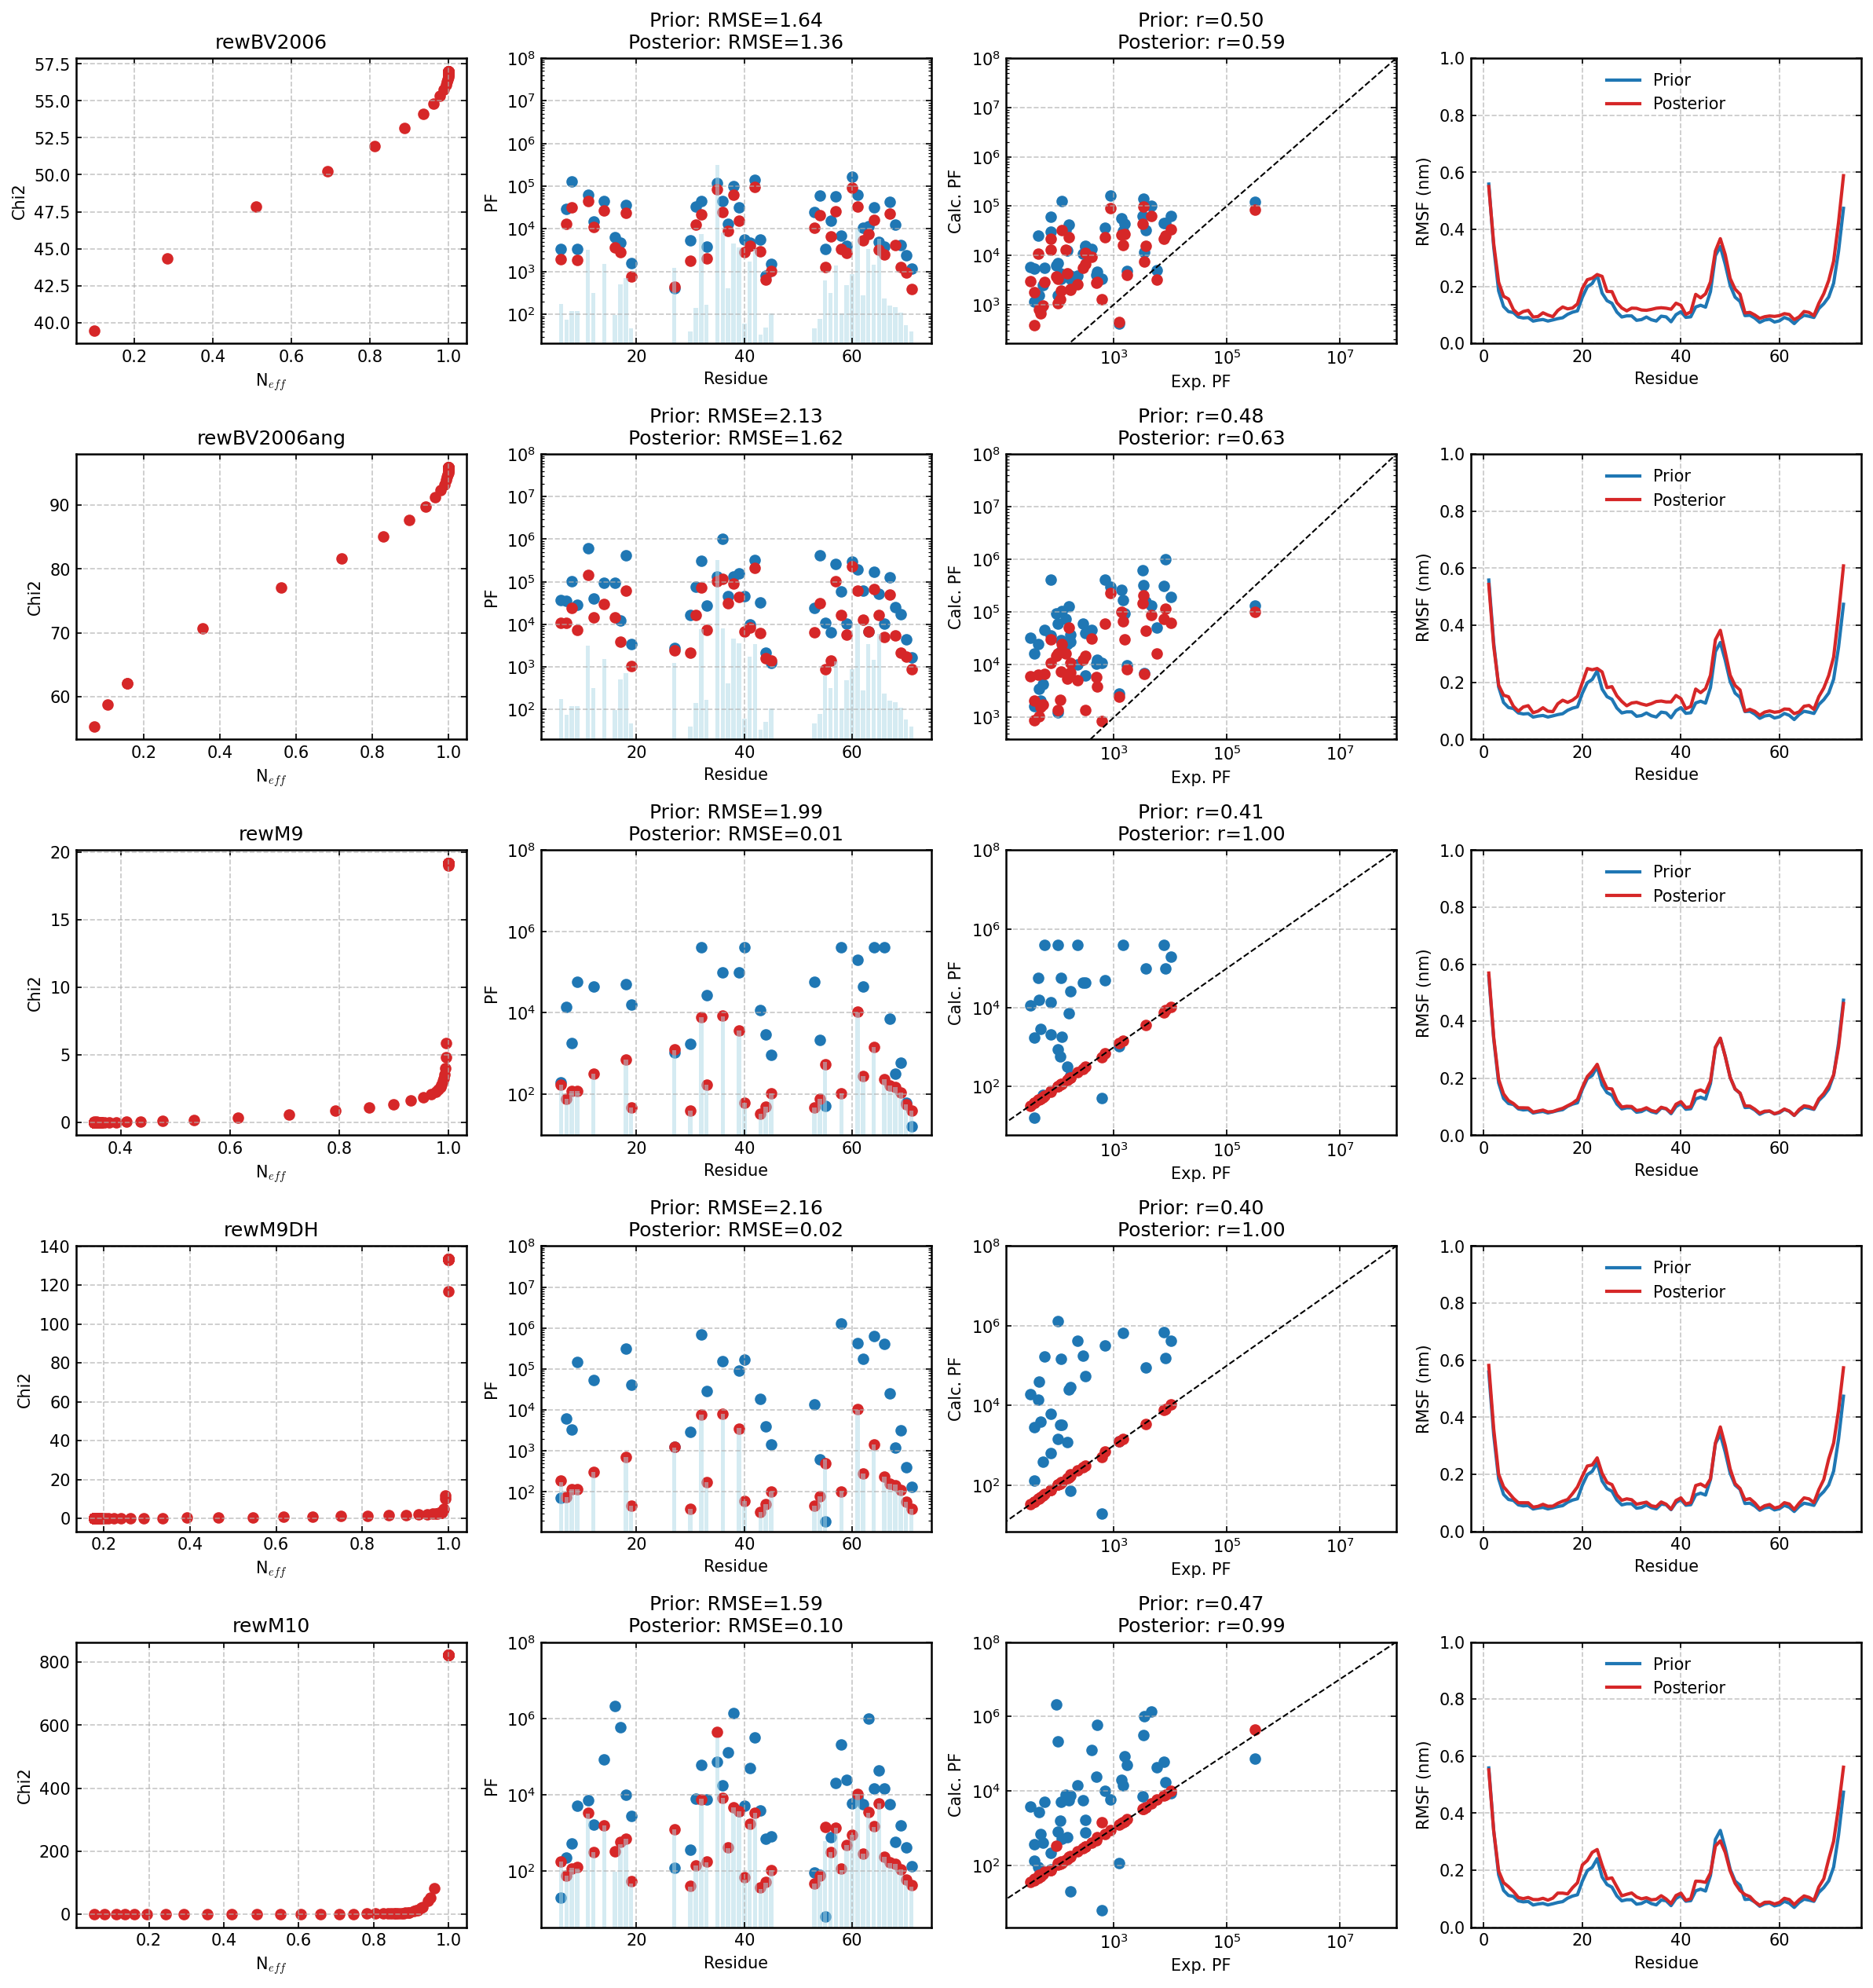

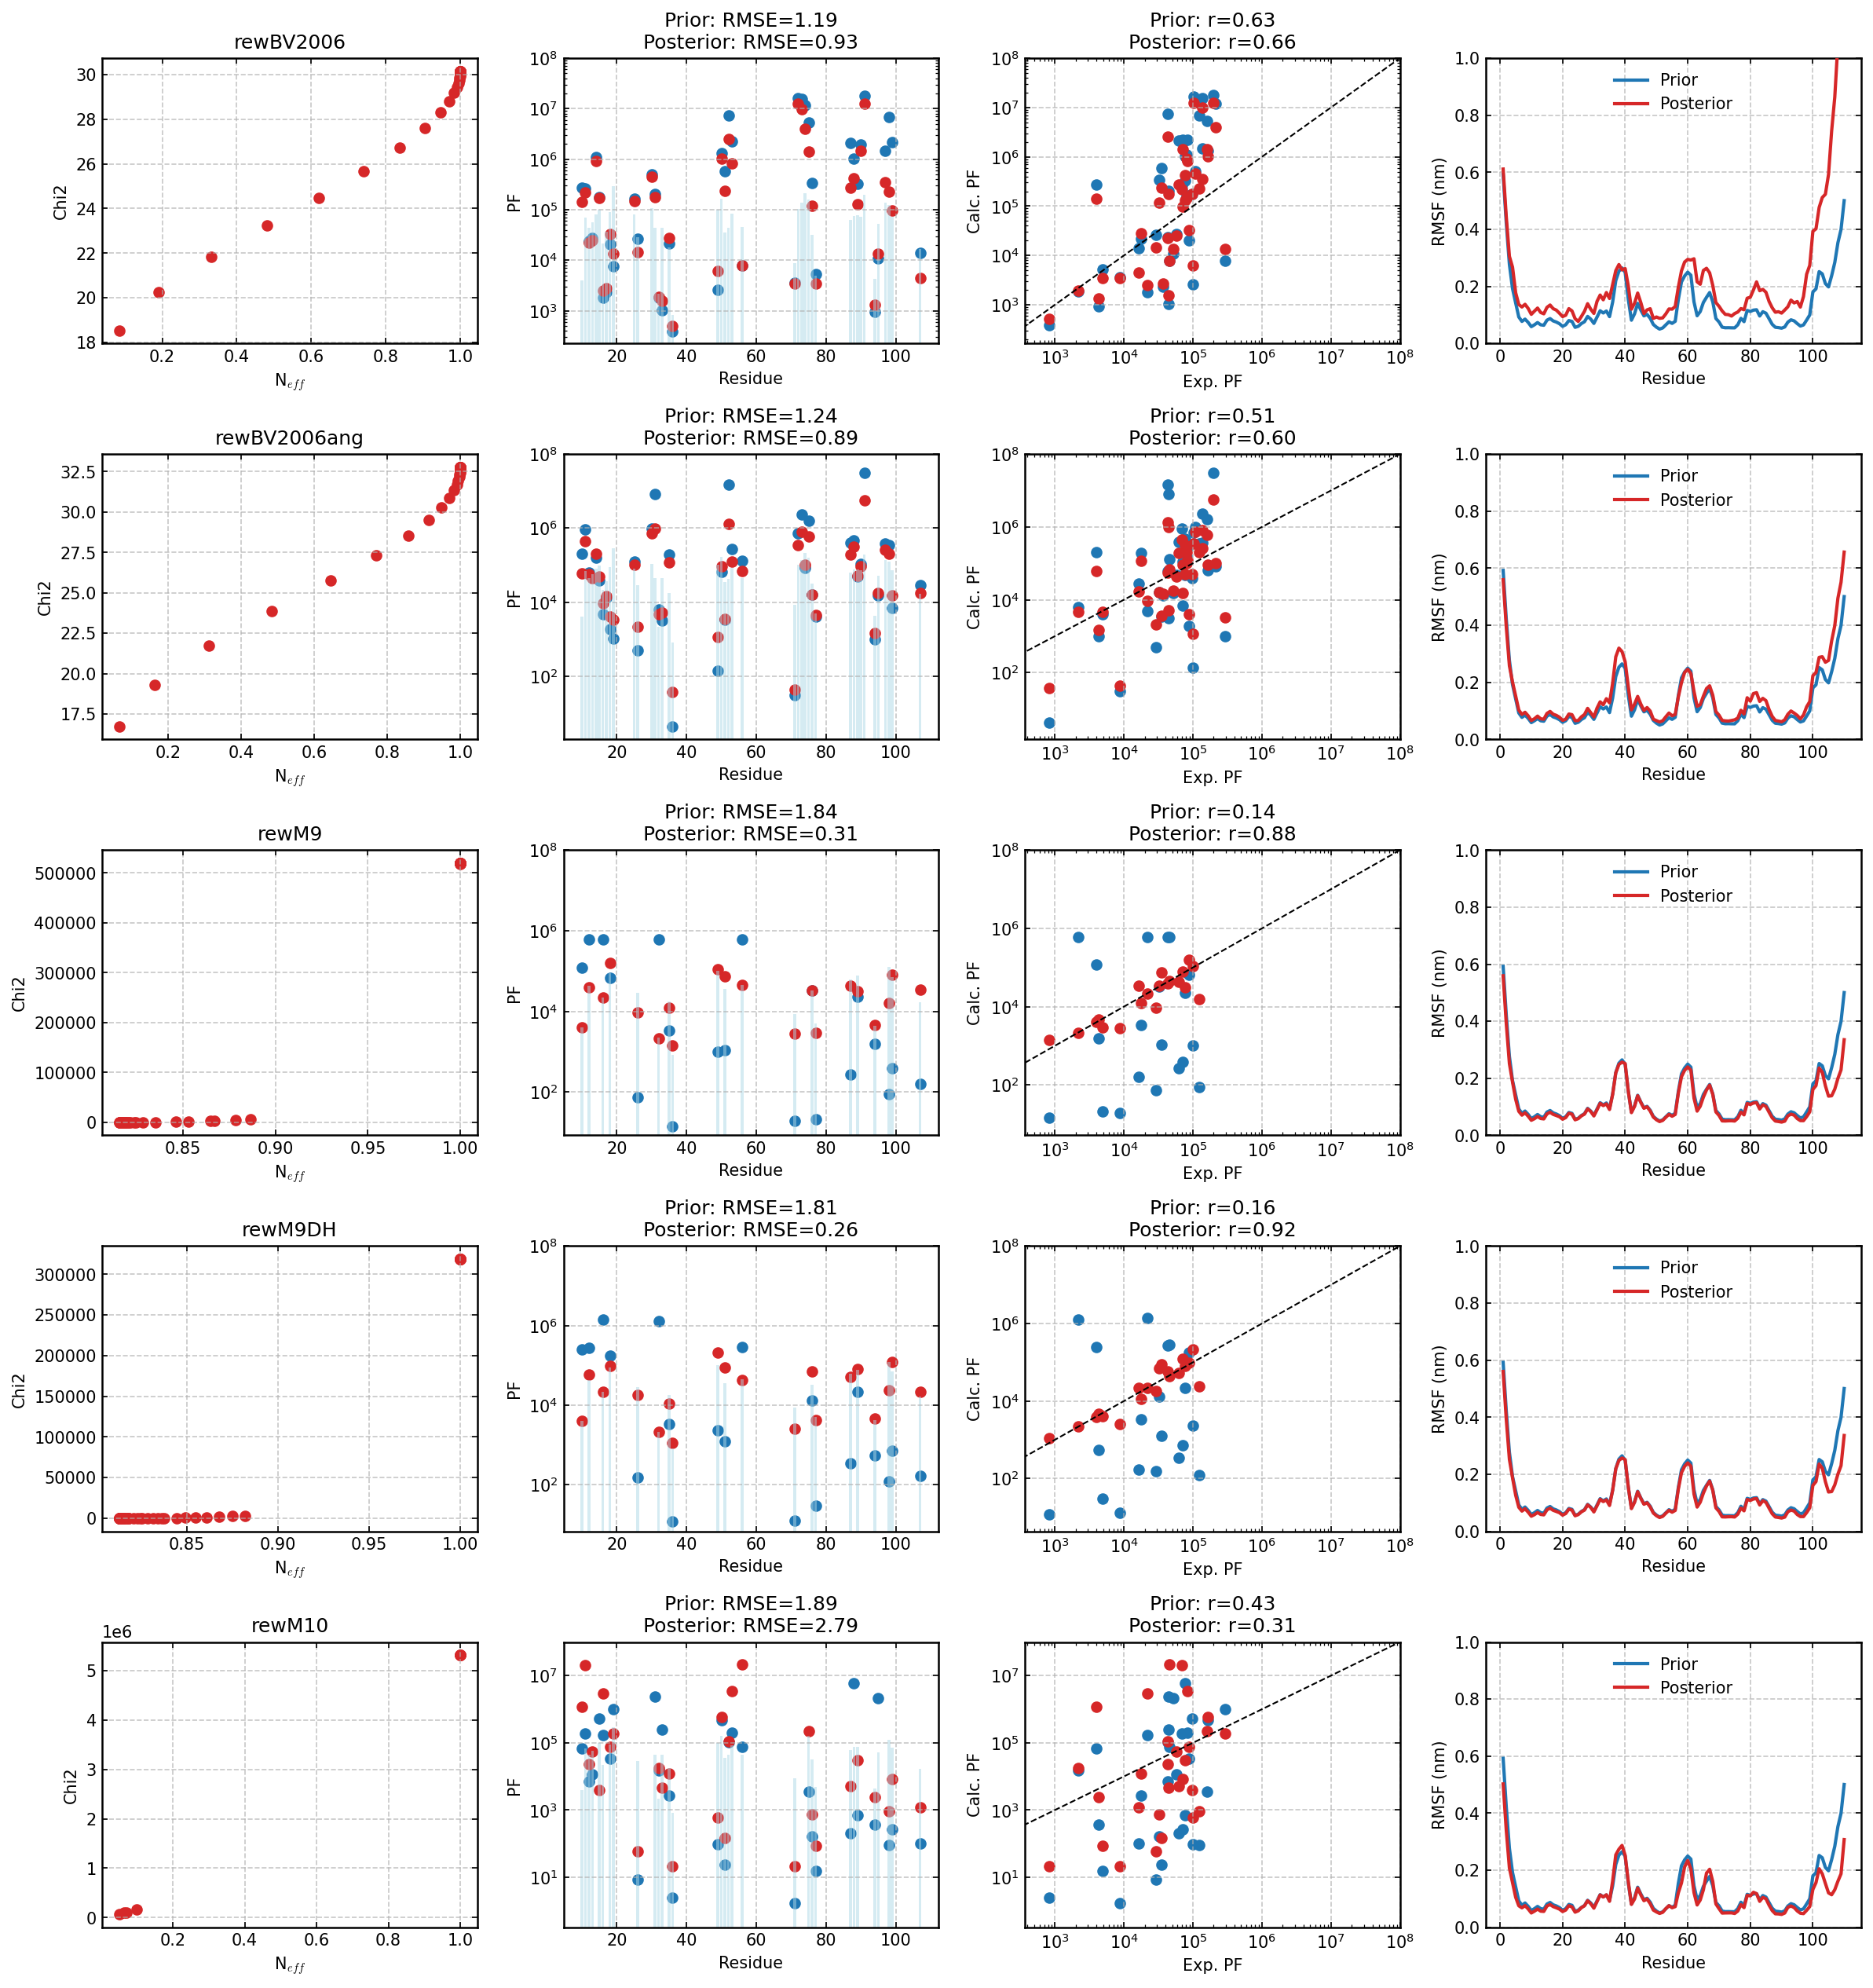

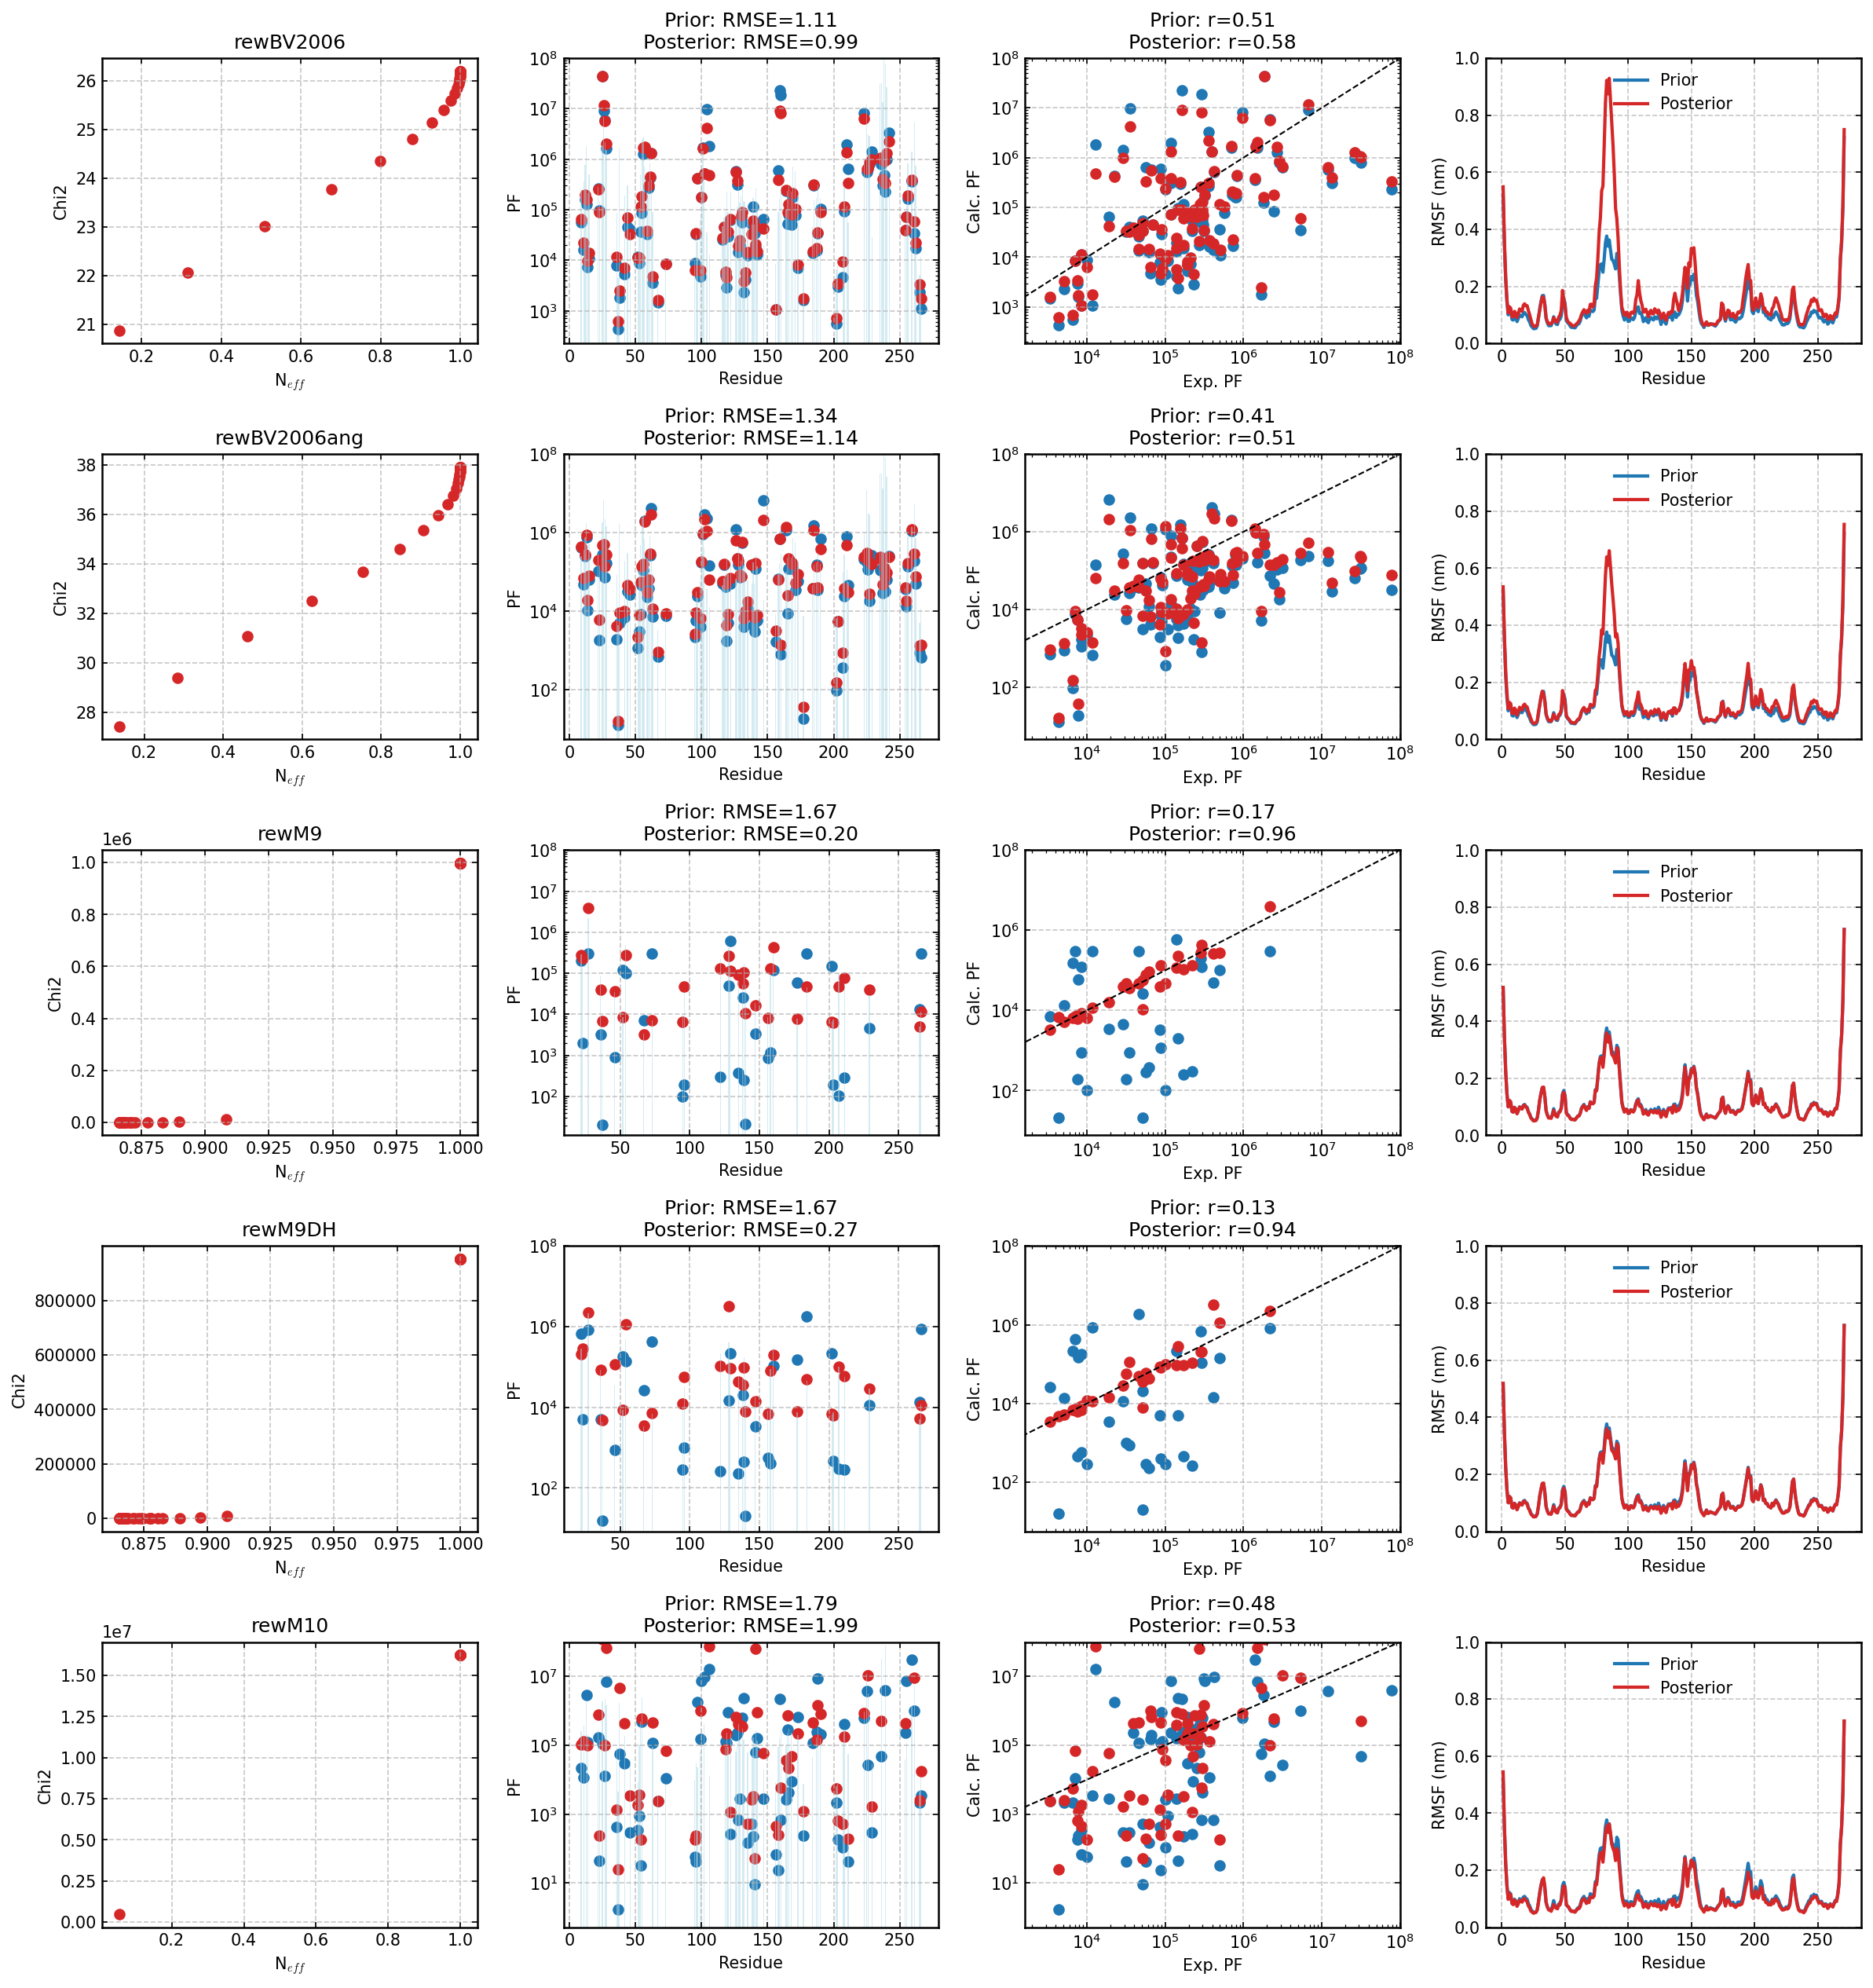

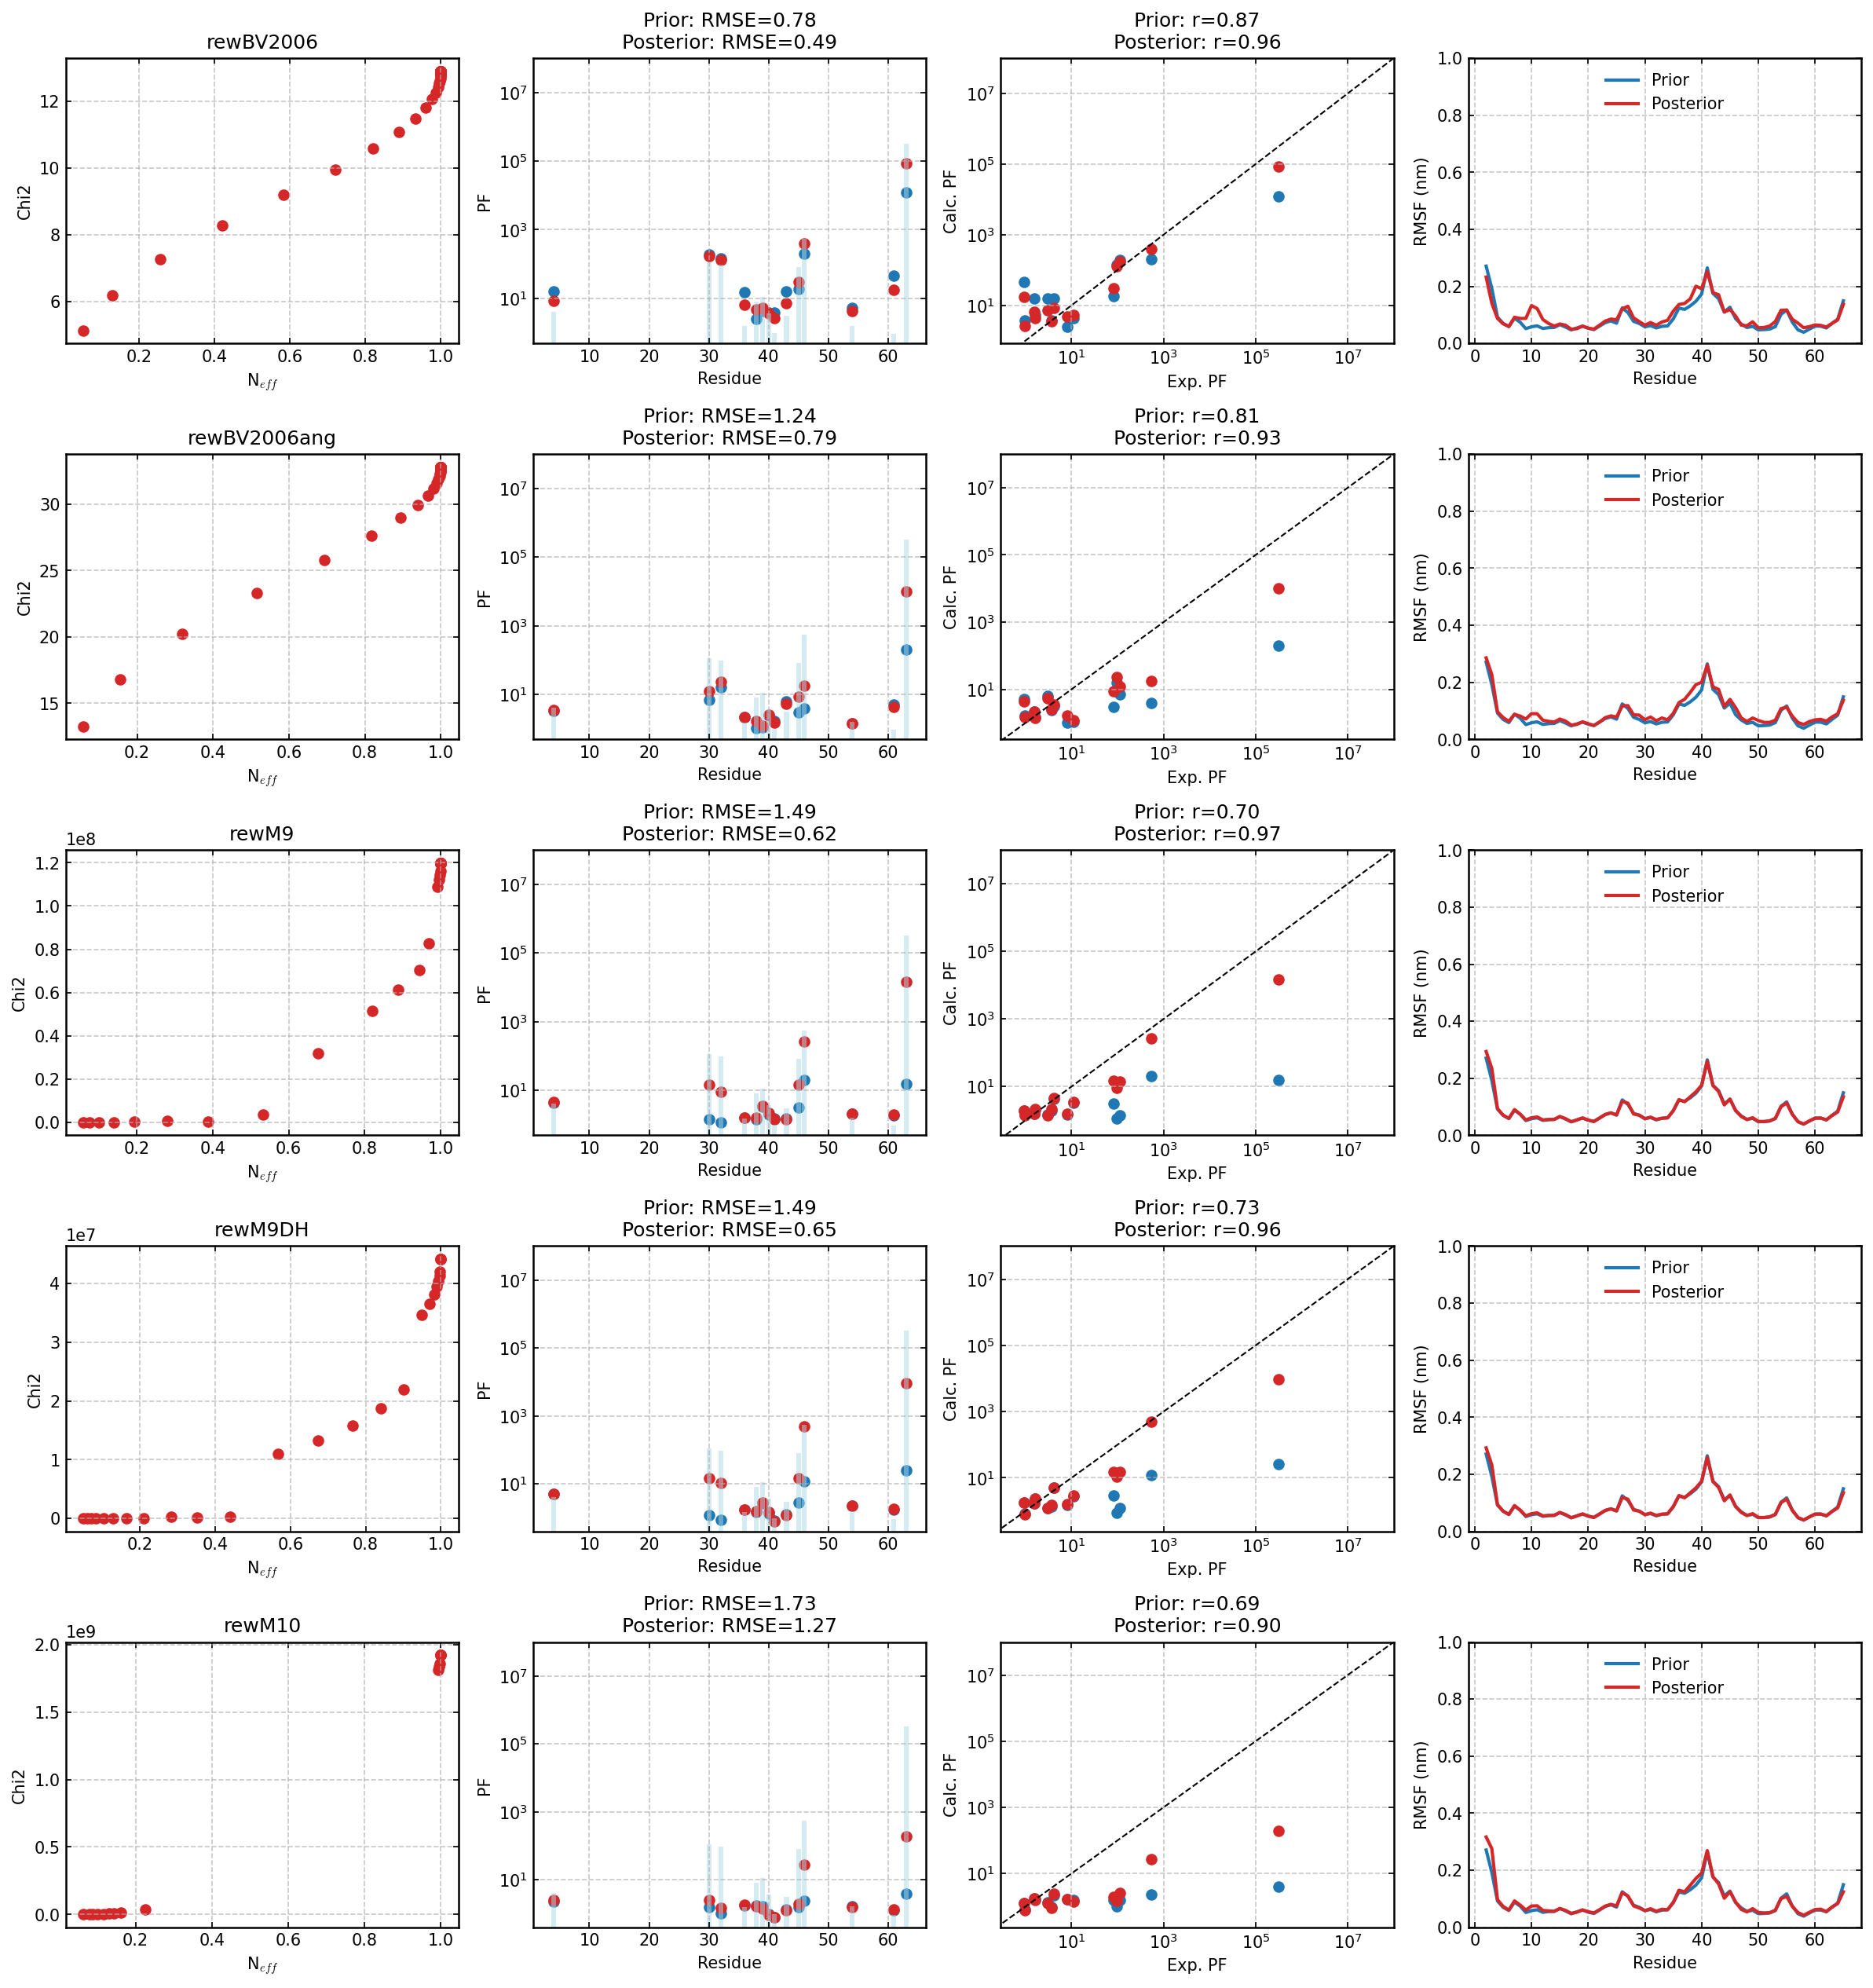

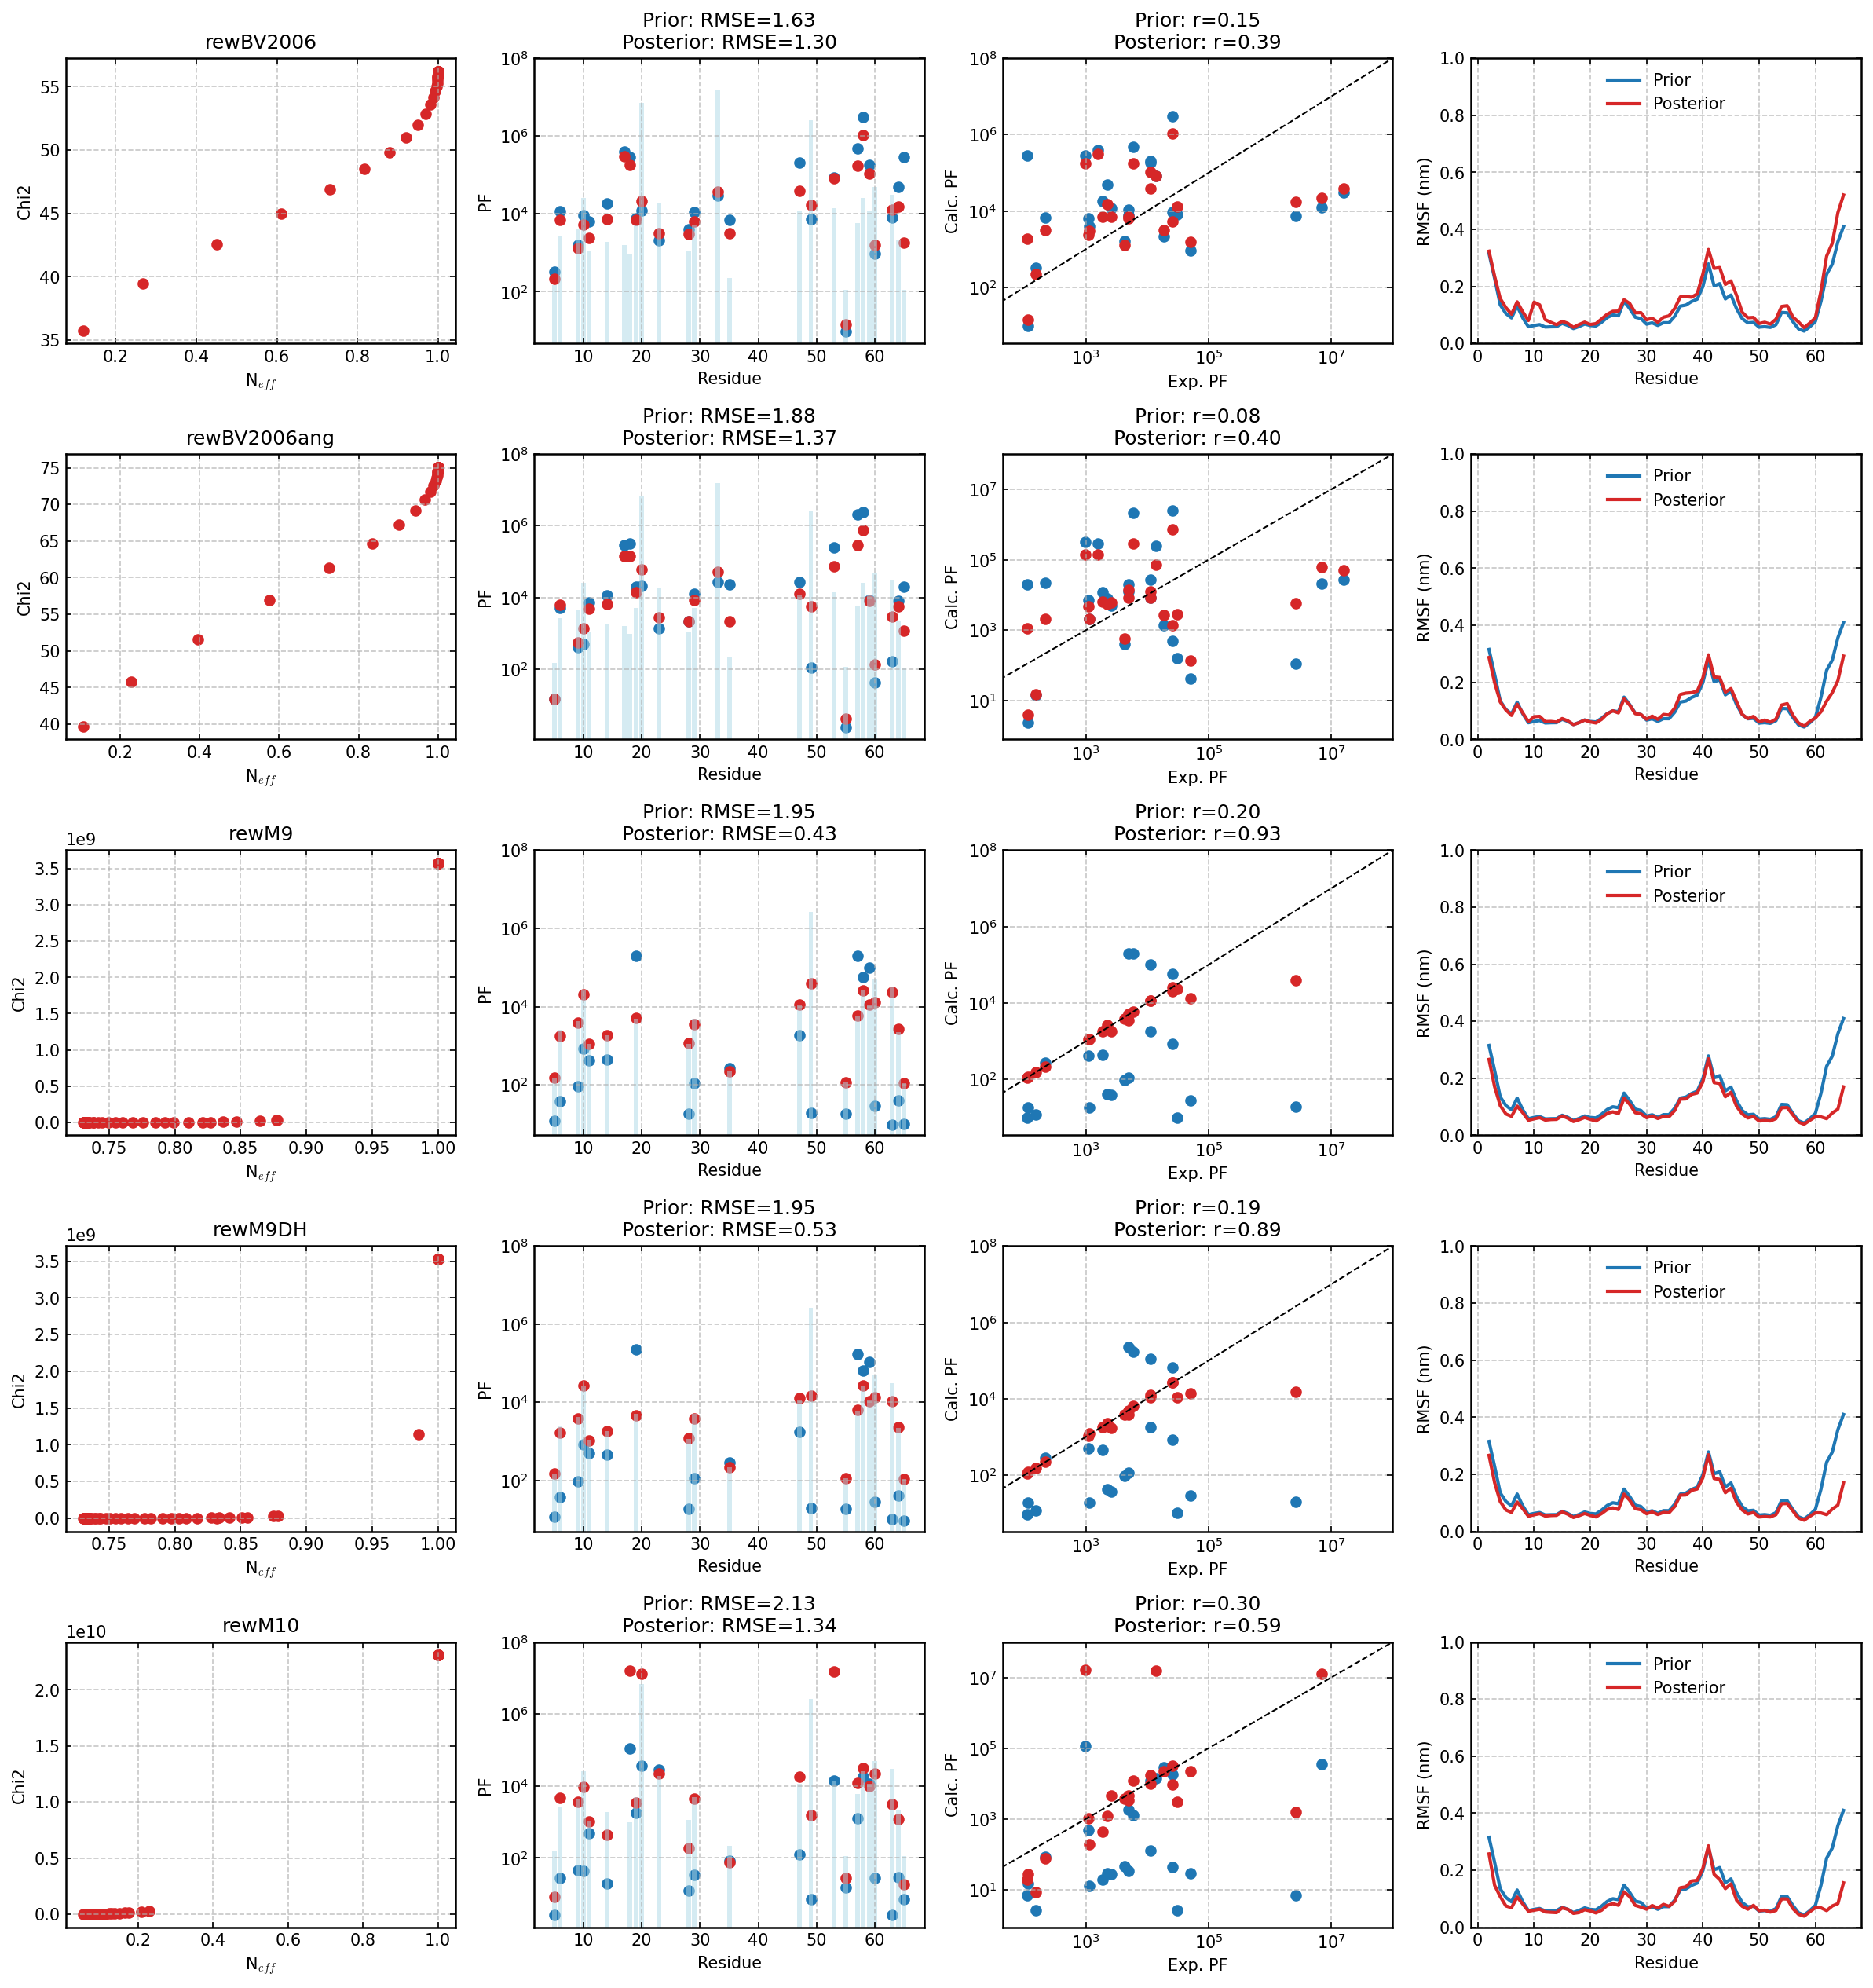

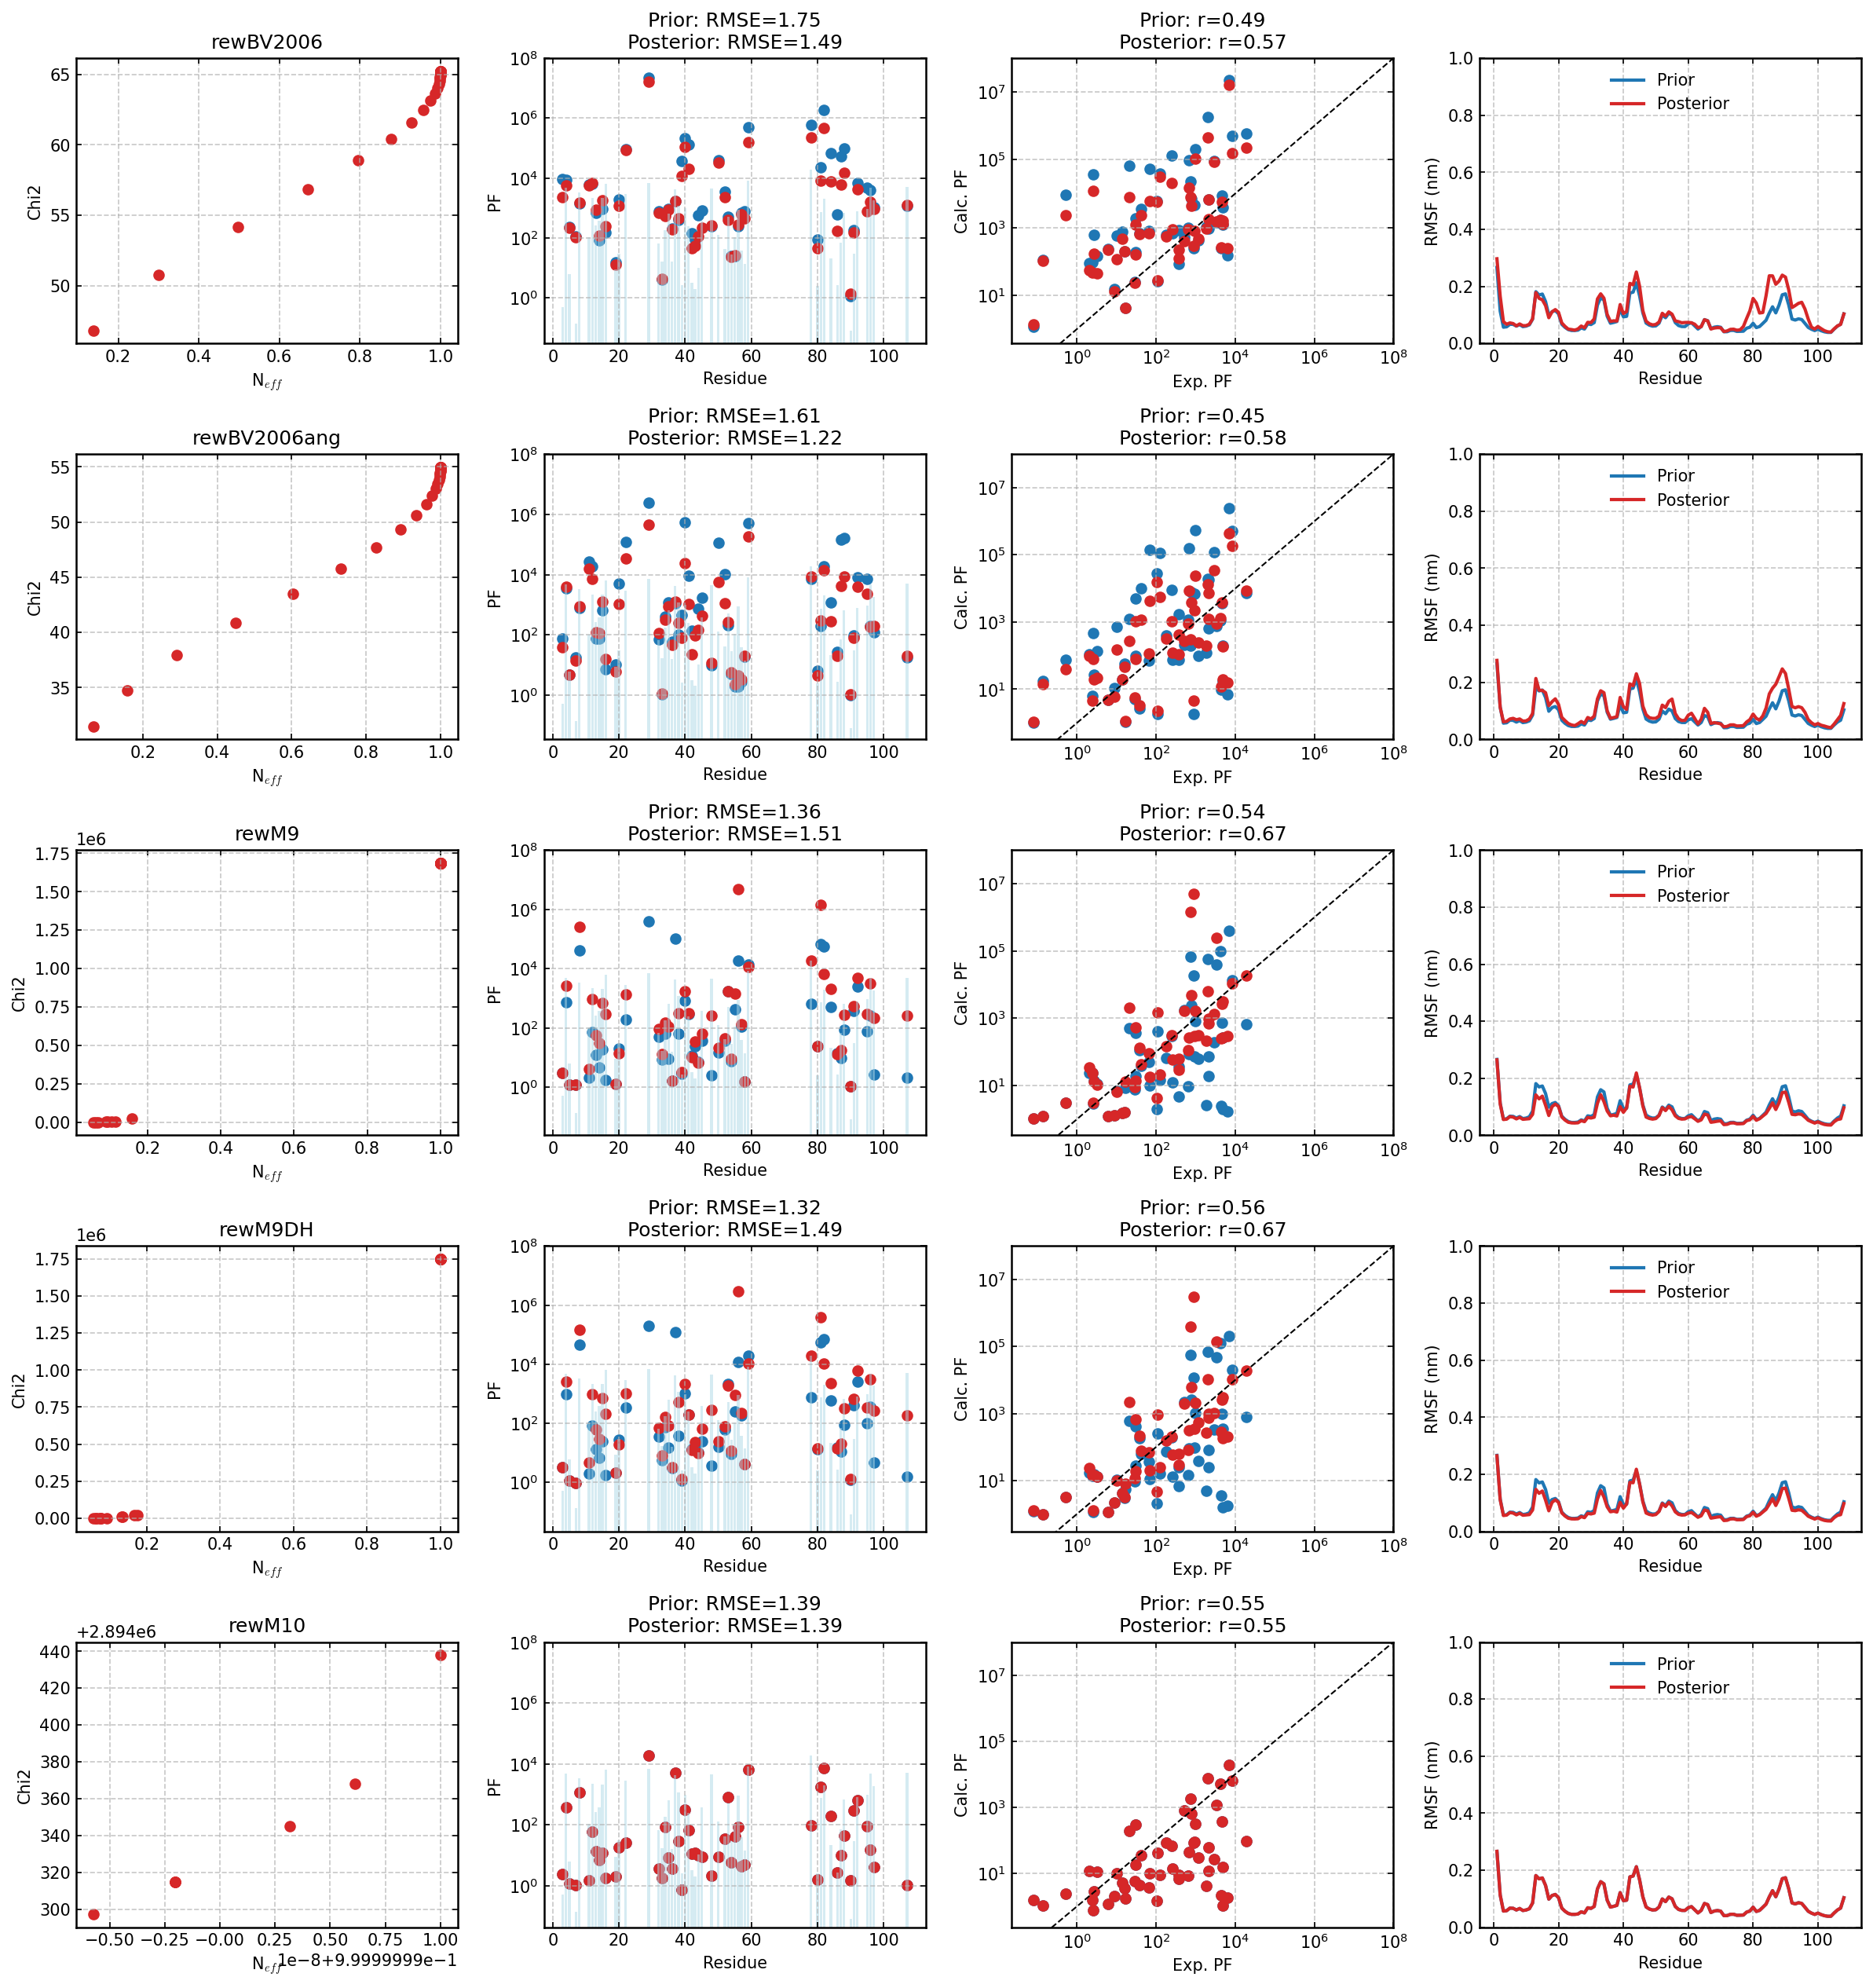

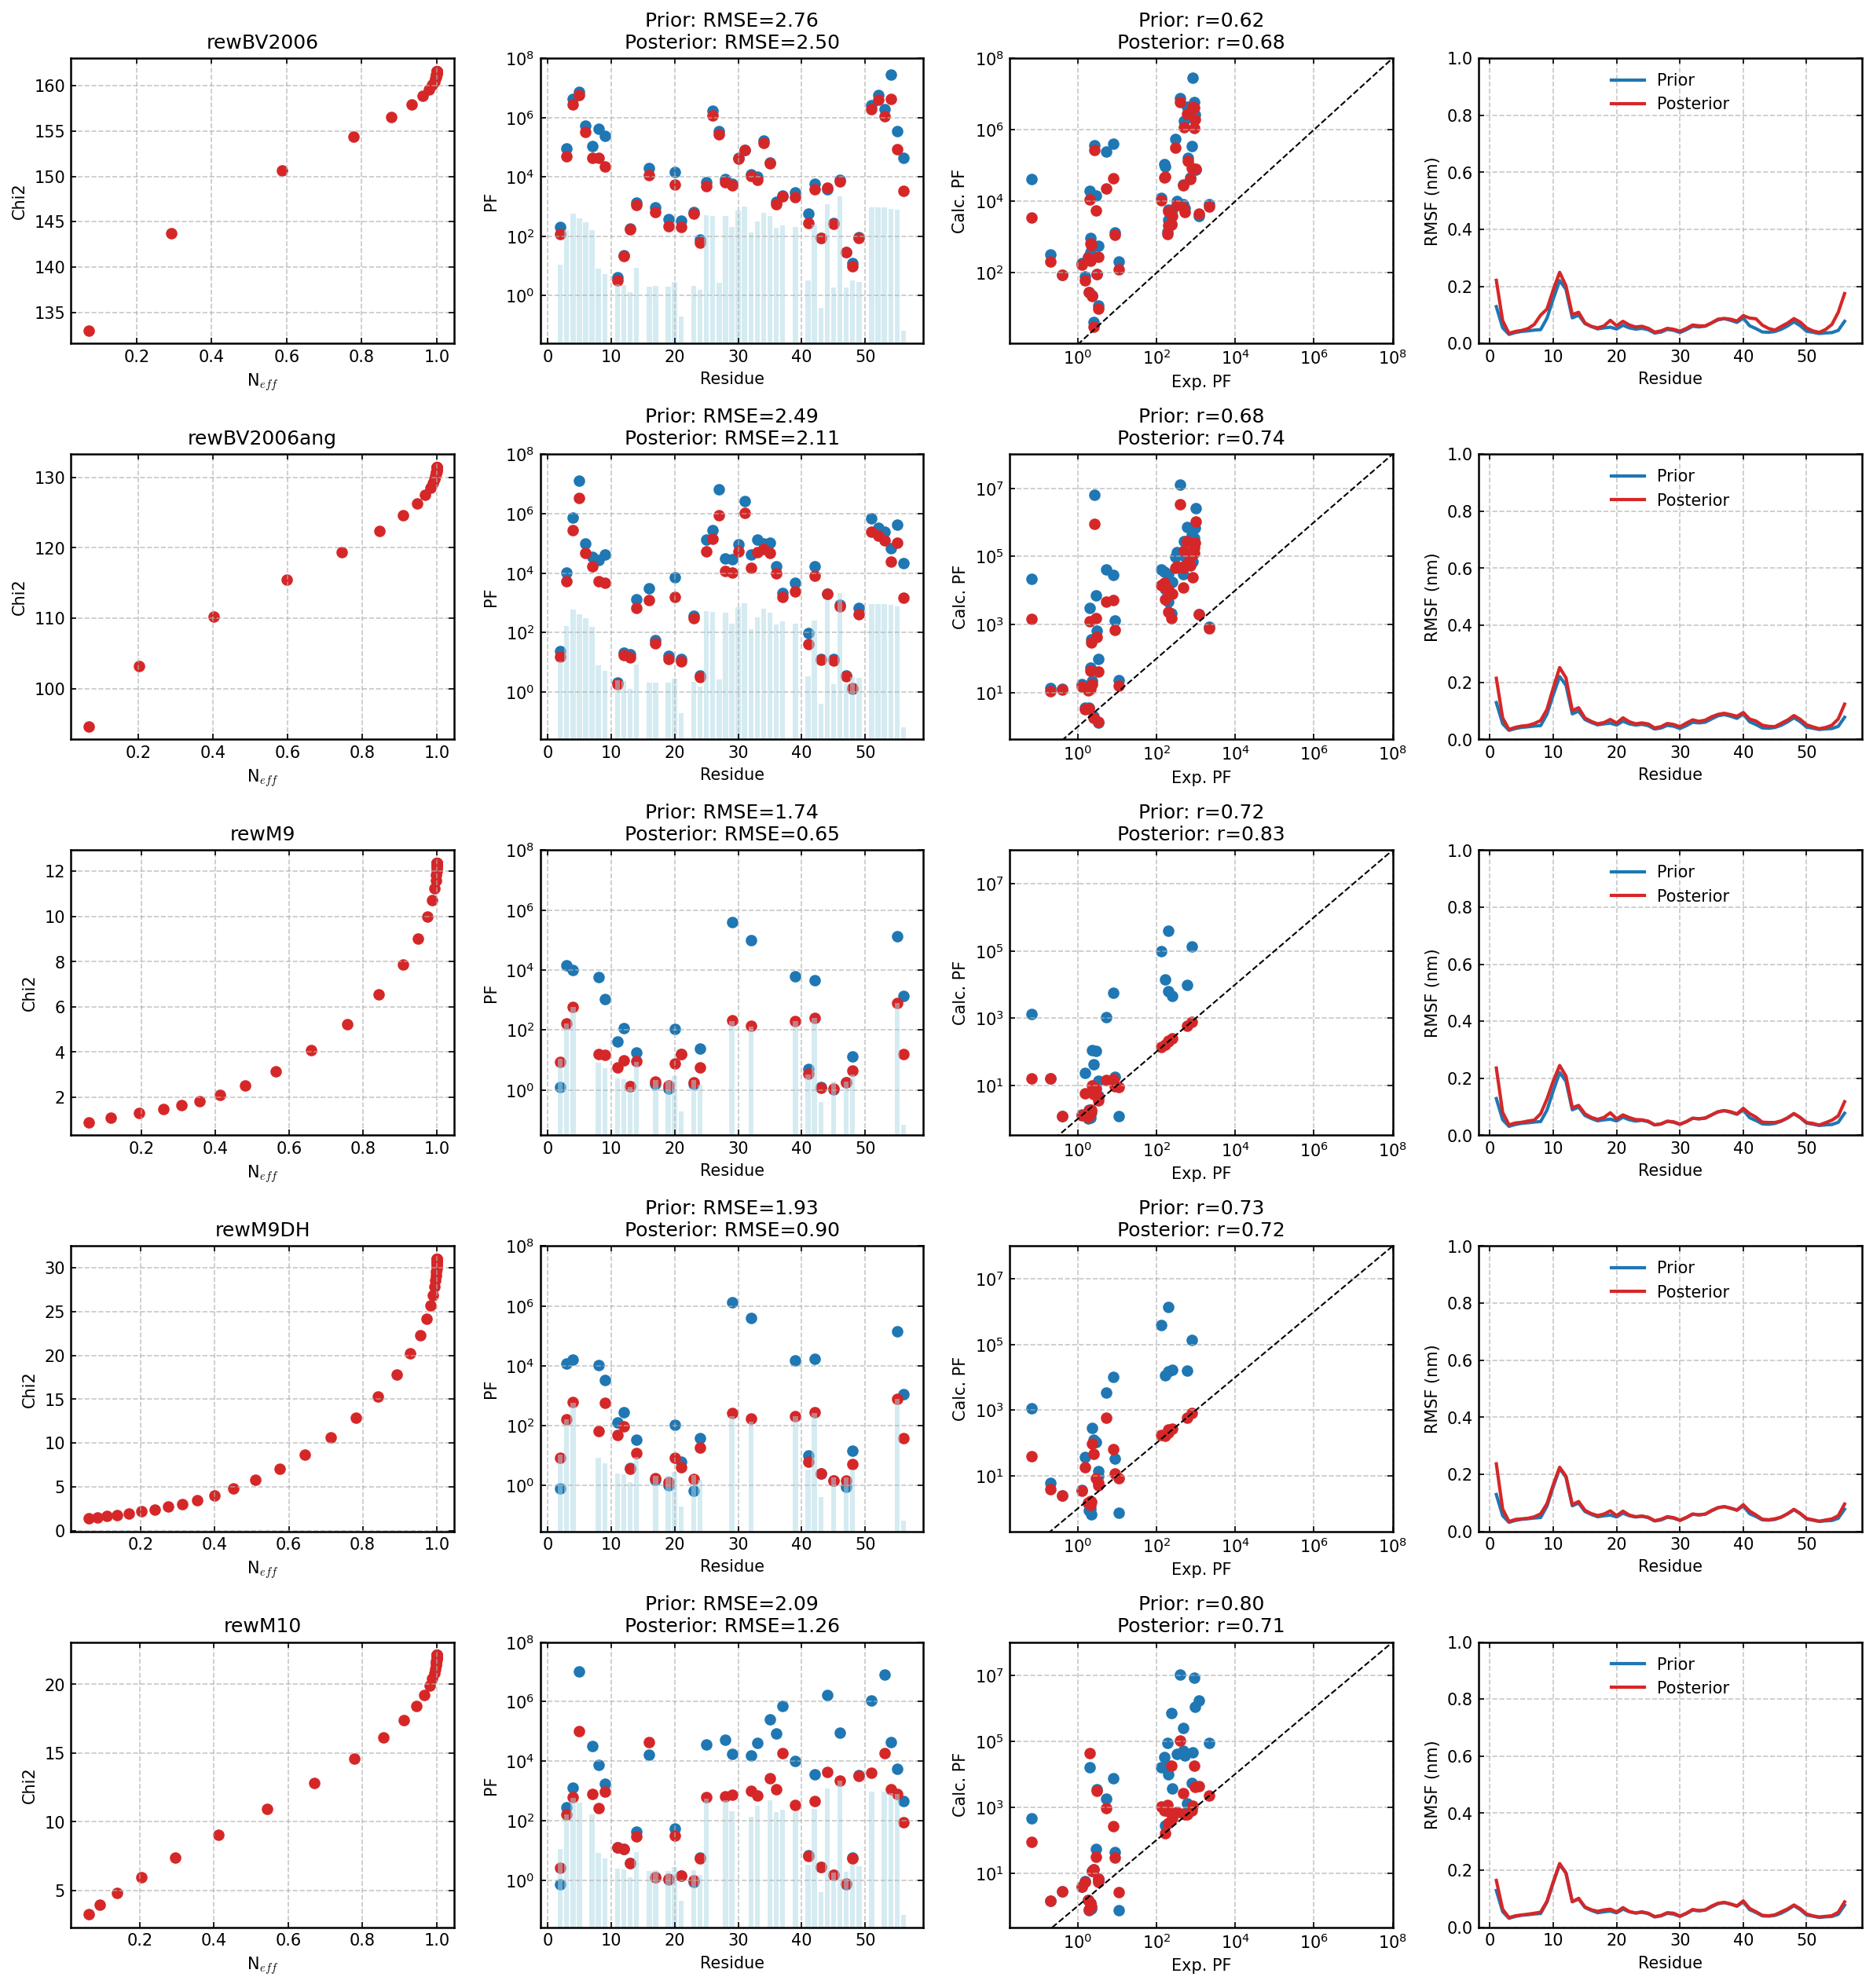

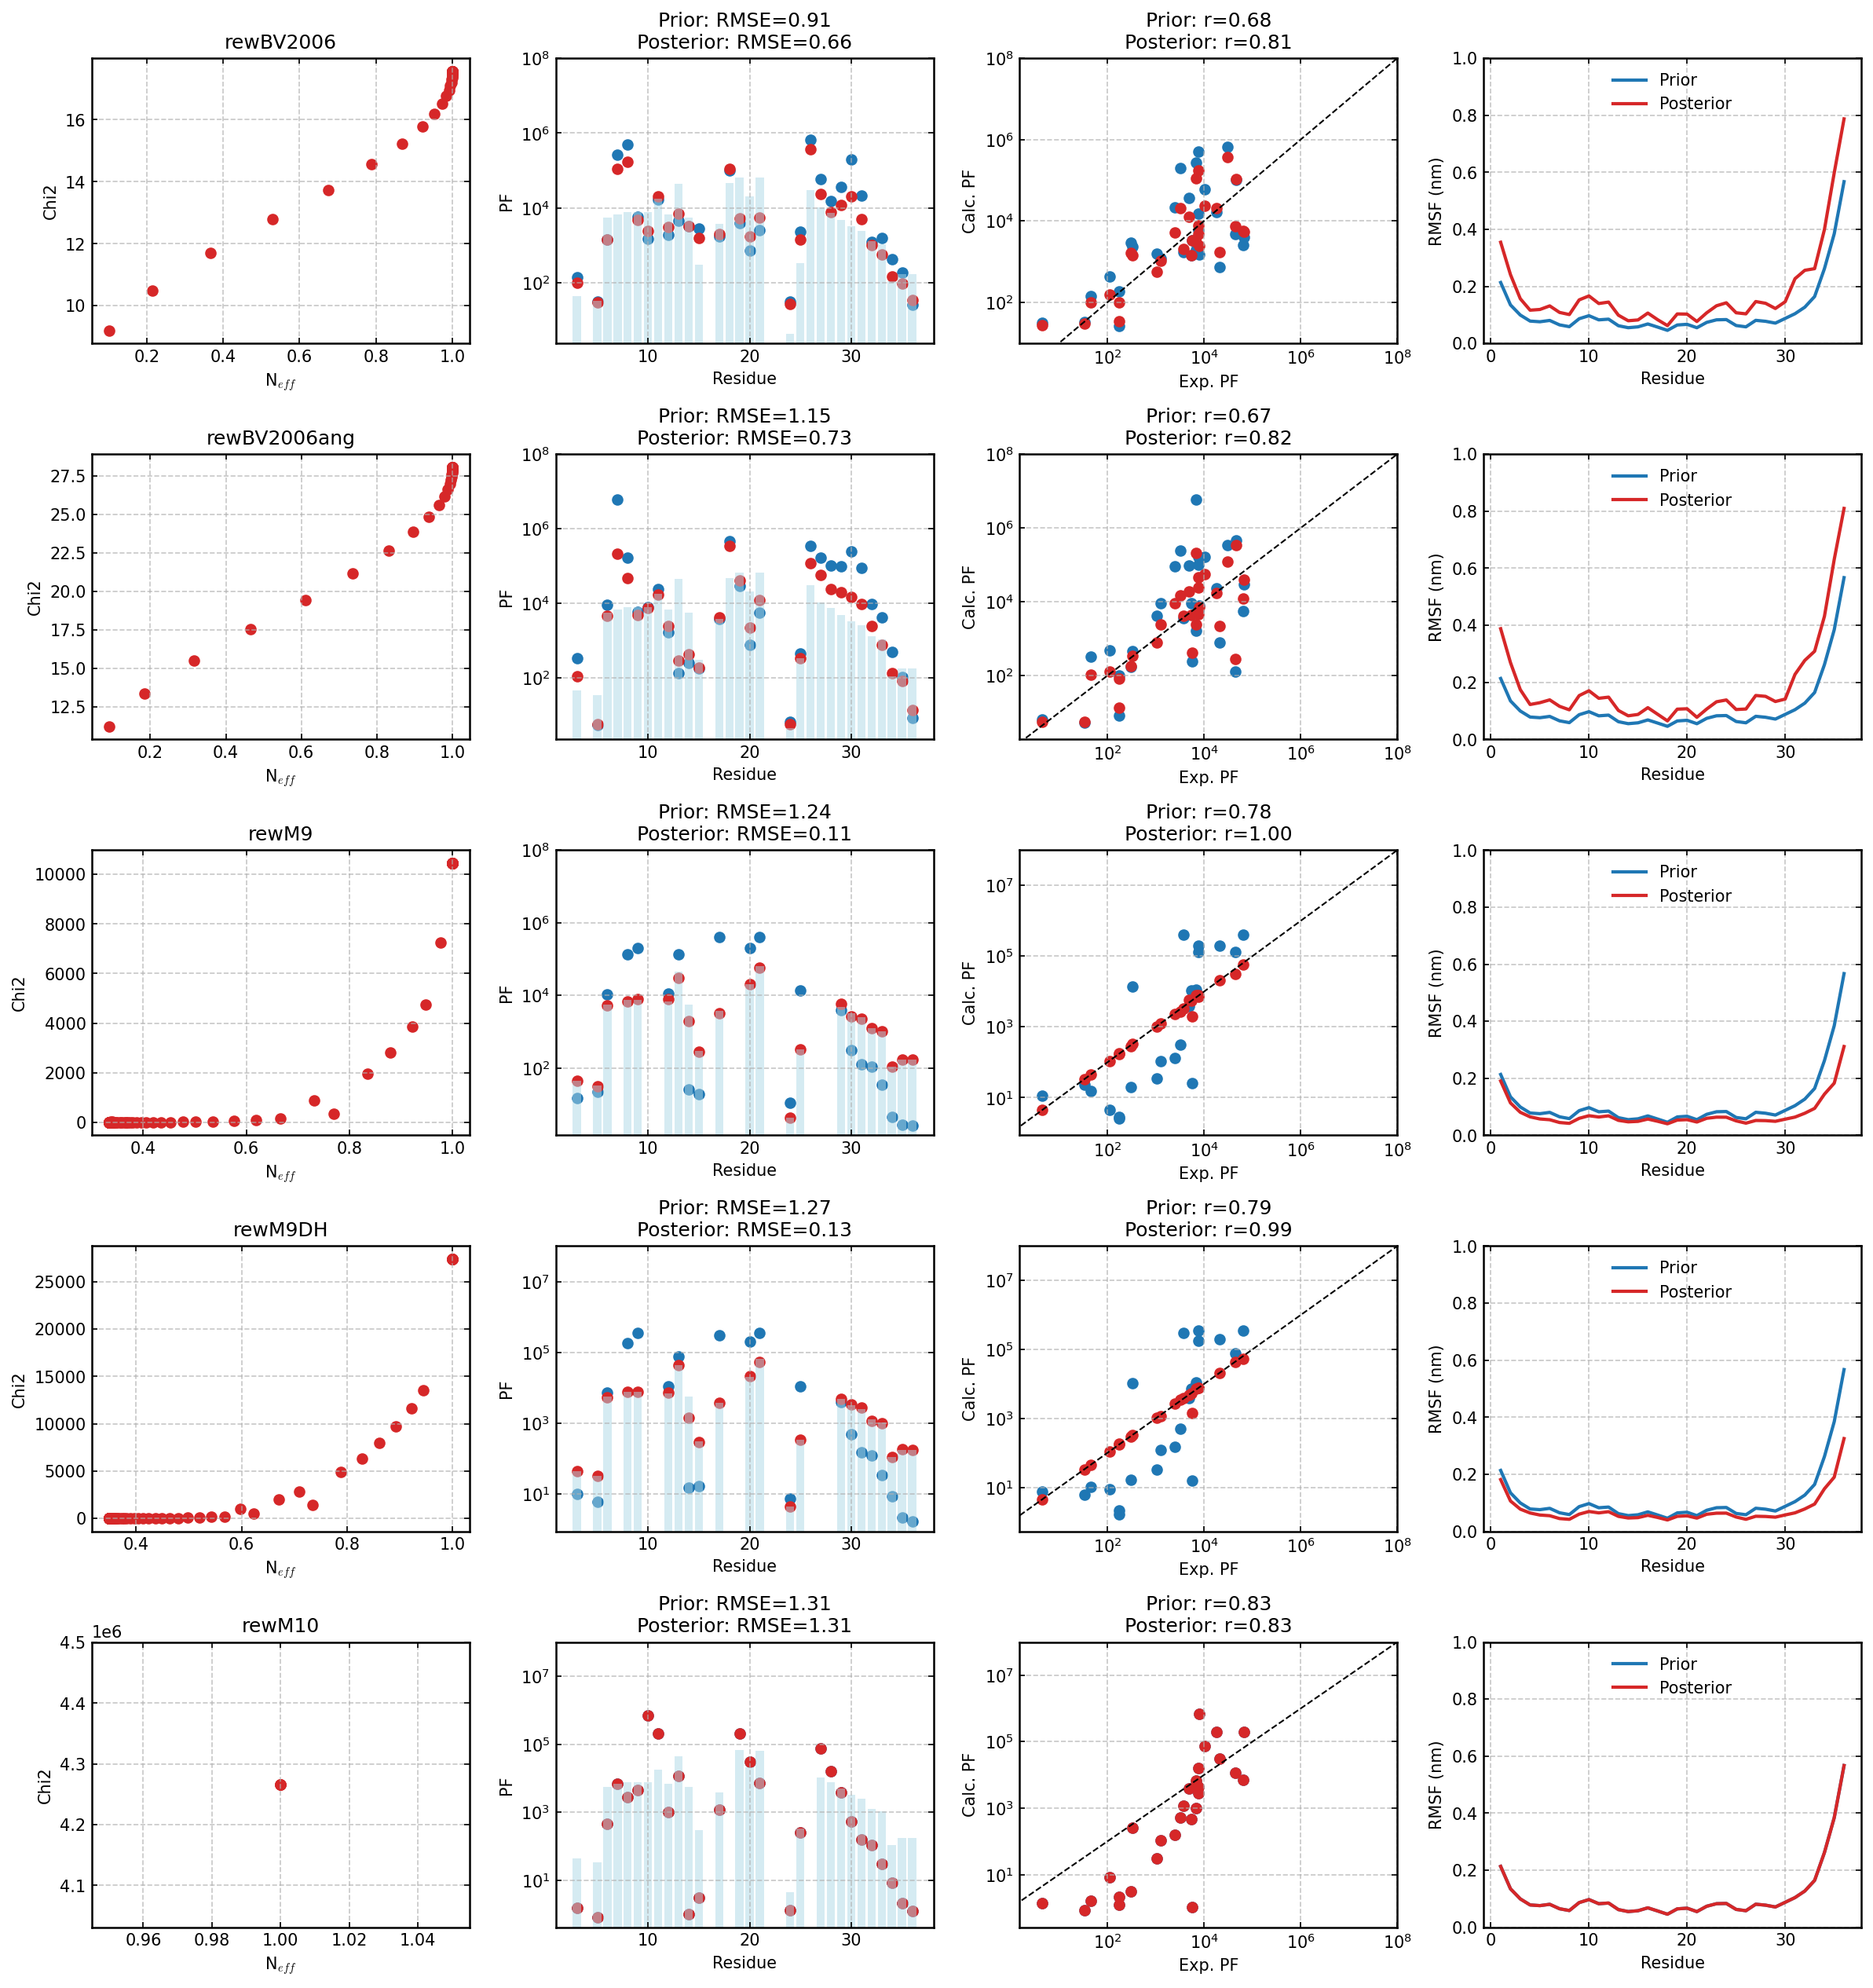

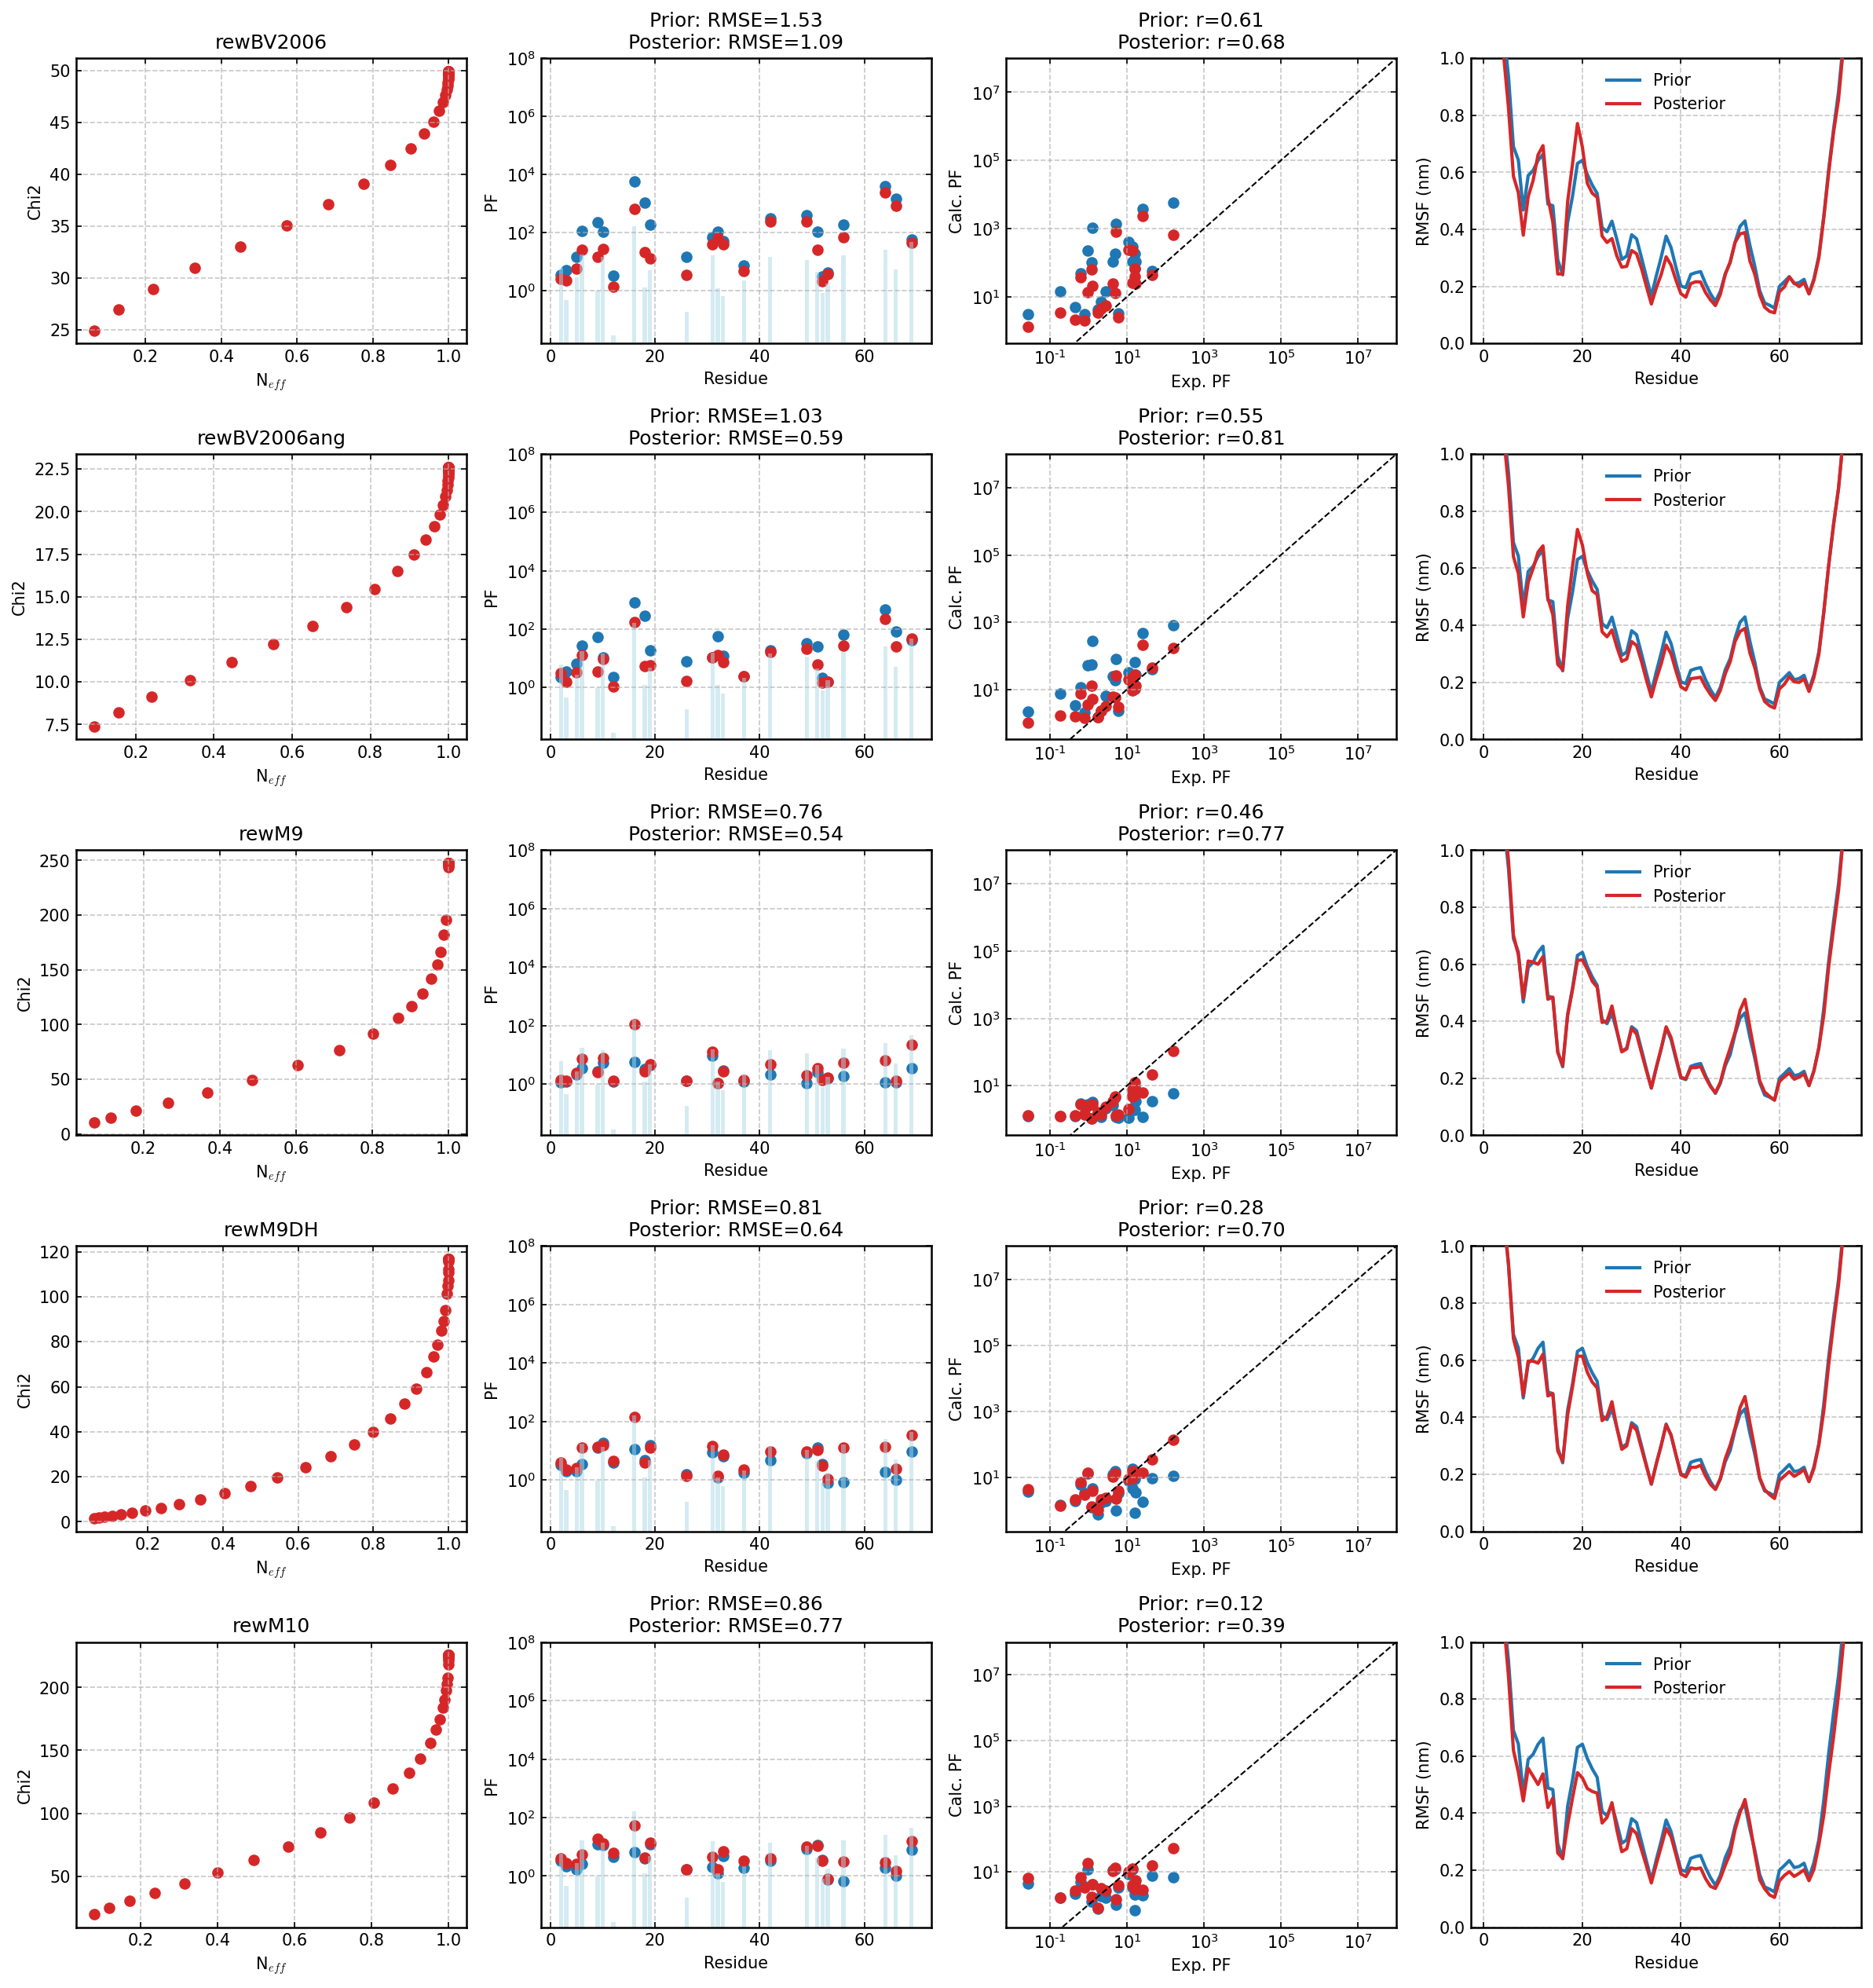

In [2]:
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM10']
proteins = ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2_wt_298K', 'CI2_wt_306K', 'FKBP12', 'GB3', 'HP36', 'Jarastatin']

for protein in proteins:
    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))


    # precalculate coordinates
    for i in range(len(traj_names)):
        u = mda.Universe(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
        if i==0:
            coords = get_coords(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
        else:
            tmpcoords = get_coords(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
            # append
            coords = np.concatenate((coords, tmpcoords), axis=0)   


    for i, model in enumerate(models):
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
        wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # posterior RMSF
        model_res, _, rmsf_prior, rmsf_post = compute_weighted_rmsf(f'../../MD_DATA/{protein}/protein.pdb', coords, weights=wopt)

        # --- Plot 1: neff vs chi2 with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, chi2, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("Chi2")
        ax.set_title(f"{model}")

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,1e8)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e10], [-10, 1e10], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,1e8)
        ax.set_xlim(0,1e8)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: RMSF data ---

        ax = axes[i, 3]

        # prior and posterior RMSE

        # experimental and ensemble averaged values
        ax.plot(model_res, rmsf_prior, color="tab:blue", label="Prior", zorder=20)
        ax.plot(model_res, rmsf_post, color="tab:red", label="Posterior", zorder=20)

        ax.set_ylabel('RMSF (nm)')
        ax.set_xlabel('Residue')

        ax.set_ylim(0,1)

        # set legend
        ax.legend(loc='upper center')

        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f"{protein}_HDXrew_RMSF.png", dpi=200, bbox_inches="tight")
        


/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

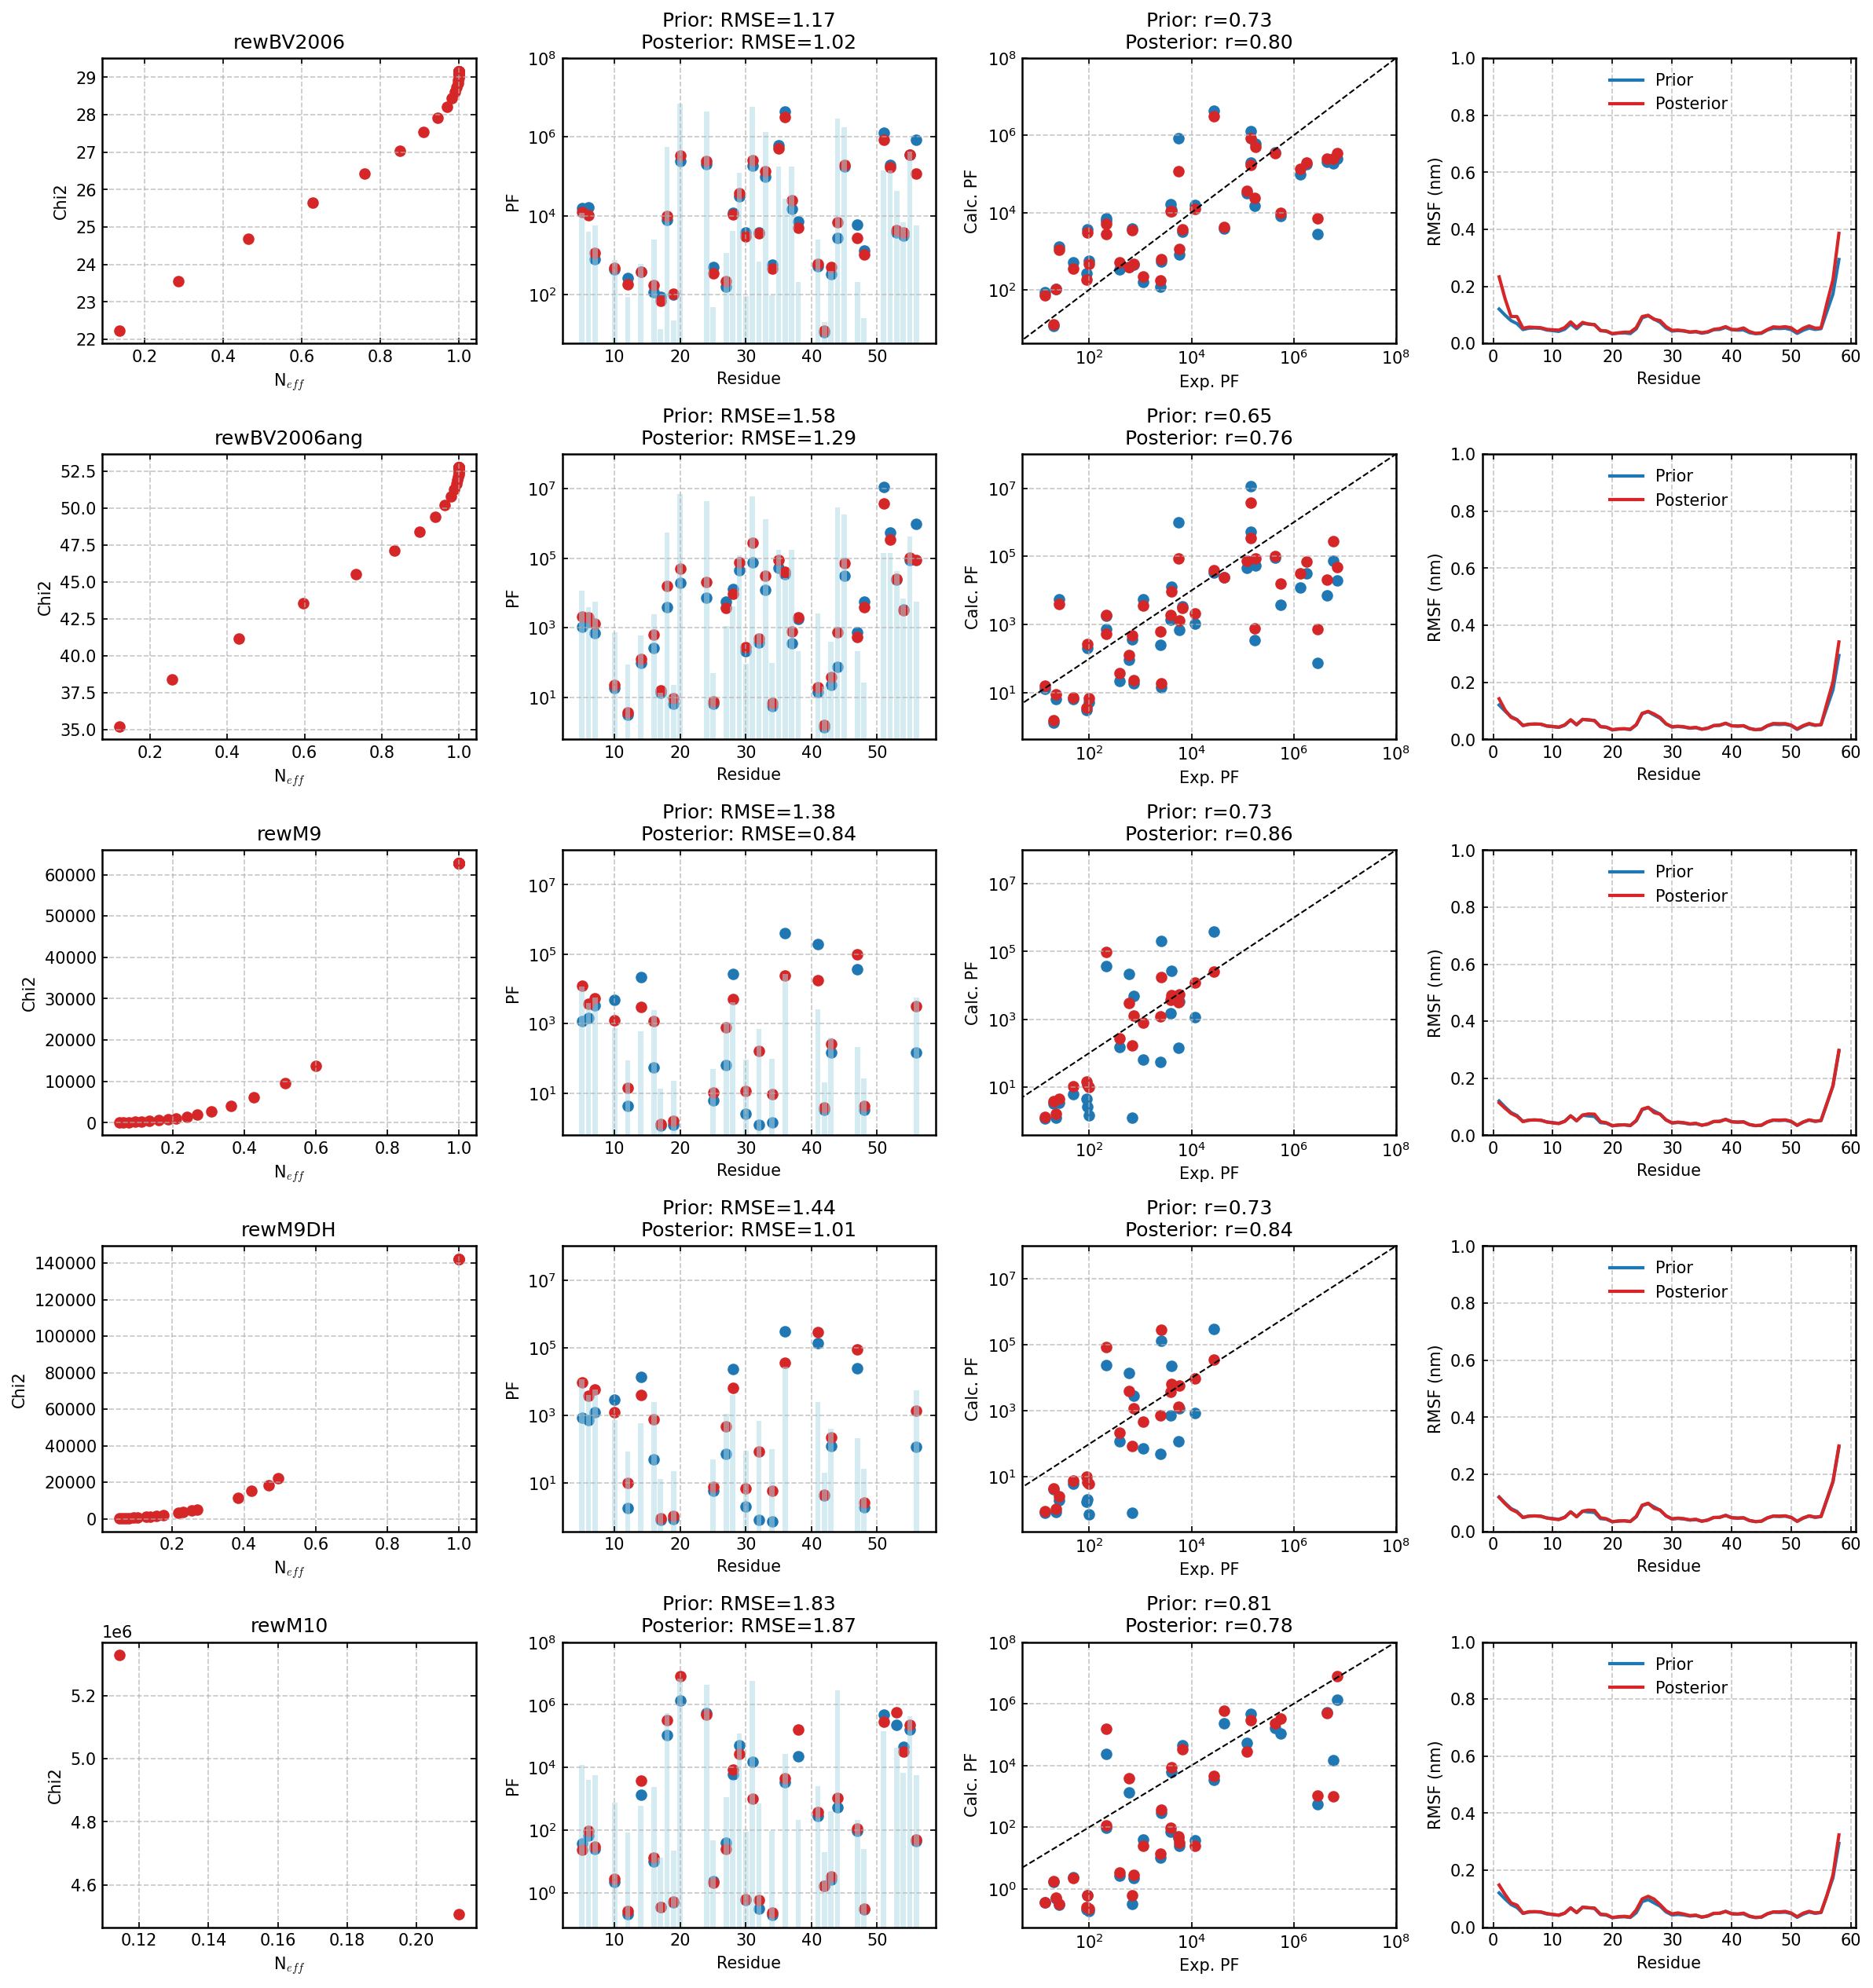

In [4]:
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM10']
proteins = ['BPTI']

for protein in proteins:
    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))


    # precalculate coordinates
    for i in range(len(traj_names)):
        u = mda.Universe(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
        if i==0:
            coords = get_coords(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
        else:
            tmpcoords = get_coords(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
            # append
            coords = np.concatenate((coords, tmpcoords), axis=0)   


    for i, model in enumerate(models):
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
        wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # posterior RMSF
        model_res, _, rmsf_prior, rmsf_post = compute_weighted_rmsf(f'../../MD_DATA/{protein}/protein.pdb', coords, weights=wopt)

        # --- Plot 1: neff vs chi2 with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, chi2, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("Chi2")
        ax.set_title(f"{model}")

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,1e8)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e10], [-10, 1e10], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,1e8)
        ax.set_xlim(0,1e8)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: RMSF data ---

        ax = axes[i, 3]

        # prior and posterior RMSE

        # experimental and ensemble averaged values
        ax.plot(model_res, rmsf_prior, color="tab:blue", label="Prior", zorder=20)
        ax.plot(model_res, rmsf_post, color="tab:red", label="Posterior", zorder=20)

        ax.set_ylabel('RMSF (nm)')
        ax.set_xlabel('Residue')

        ax.set_ylim(0,1)

        # set legend
        ax.legend(loc='upper center')

        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f"{protein}_HDXrew_RMSF.png", dpi=200, bbox_inches="tight")
        


In [18]:
asym_err.shape

(2, 491)